<a href="https://colab.research.google.com/github/koffifidelek59-collab/nyc-airbnb-analytics/blob/main/NYC-Airbnb-Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# MIT License
#
#@title Copyright (c) 2026 KOUAME Koffi Fidèle { display-mode: "form" }
#
# Permission is hereby granted, free of charge, to any person obtaining a
# copy of this software and associated documentation files (the "Software"),
# to deal in the Software without restriction, including without limitation
# the rights to use, copy, modify, merge, publish, distribute, sublicense,
# and/or sell copies of the Software, and to permit persons to whom the
# Software is furnished to do so, subject to the following conditions:
#
# The above copyright notice and this permission notice shall be included in
# all copies or substantial portions of the Software.
#
# THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
# IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
# FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL
# THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
# LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING
# FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER
# DEALINGS IN THE SOFTWARE.

### Open in Google Colab

You can run this notebook directly in [Google Colab](https://colab.research.google.com) without installing anything locally. Just click the badge below:

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/koffifidelek59-collab/nyc-airbnb-analytics/blob/main/NYC-Airbnb-Analytics.ipynb)

💡**Note on Hardware**

The whole analysis runs on a standard CPU in under one minute. No GPU is required.

# Data Analysis Internship, Final Project: New York City Airbnb Market Analysis - Where, What and at Which Price? Listing Types, Areas, Prices, Demand and Hosts of 48,895 Listings (2019)

## Author
1. KOUAME Koffi Fidèle - WASCAL IMP-EGH (Energy and Green Hydrogen Technology, System Analysis), Abdou Moumouni University, Niamey.

## Contact info
Any correspondence via KOUAME Koffi Fidèle - koffifidelek59@gmail.com

## Overview

This is the **final project of the Data Analysis track (Task 12)**. Airbnb has become a large part of the accommodation offer of New York City. Hosts want to know where and at which price to list, Airbnb wants to understand supply and demand in each area, and the city follows how short-term rentals spread across neighbourhoods. This notebook answers these questions point by point with **one dataset only, the one supplied**, from the raw file to an **interactive Power BI dashboard**, and ends with data-driven recommendations.

> **Raw data → Understanding → Quality audit → Cleaning → KPIs → One analysis per question → Statistical tests and price model → Power BI dashboard → Insights & recommendations**

The data: **`AB_NYC_2019.csv`**, 48,895 Airbnb listings of New York City in 2019, supplied for the project, with location, room type, nightly price, minimum stay, reviews, host and availability, plus a grey map of the city (`New_York_City_.png`) used as the background of the maps.

The main contributions of this notebook are:

*   **A complete data understanding and quality audit:** meaning and type of every column, the questions the data can and **cannot** answer (there is **no rating** column), missing values explained (all 10,052 missing review dates belong to listings never reviewed), impossible prices ($0), placeholder prices ($9,999, $10,000), minimum stays above one year, and even a map file that is a JPEG named `.png`.
*   **A traceable cleaning** in 10 logged steps: 48,895 raw listings → **48,645 clean listings (99.49 % kept)**, exported with derived columns for the analysis and the dashboard.
*   **One answer per question of the brief**, each with a chosen visual (bars, maps, box plots, histogram, hexbin, bubble chart) and an interpretation.
*   **Evidence, not only charts:** non-parametric tests with effect sizes, rank correlations with confidence intervals, and a **multiple regression of the price** that measures each factor with the others held constant.
*   **A business reading:** each finding ends with what a host, Airbnb or the city can do with it.

## Study Goals
By the end of this notebook, the reader will be able to:

1. **Understand the dataset**: source, size, meaning, unit and type of each column, and what it can and cannot answer.
2. **Clean it** with documented rules (missing values, duplicates, types, inconsistent values, outliers, unnecessary columns) and export the cleaned dataset.
3. **Answer the seven questions** of the brief (listing types, active areas, prices by area, price and reviews, price factors, best performers, patterns), each with a figure and an interpretation.
4. **Test the patterns** with non-parametric tests, rank correlations and a price model.
5. **Build the Power BI dashboard** page by page, with its measures, filters and expected values.
6. **Turn the findings into decisions** for hosts, for Airbnb and for the city.

# Table of Contents
*   [1. Understanding the Analytical Task](#analytical-task)
*   [2. Target Audience](#target-audience)
*   [3. Software Requirements](#software-requirements)
*   [4. Data Description & Datasheet](#data-description)
*   [5. Data Loading](#data-loading)
*   [6. Data Understanding: Columns and Types](#data-understanding)
*   [7. Data Quality Audit](#data-quality)
*   [8. Data Cleaning & Cleaned Dataset](#data-cleaning)
*   [9. KPIs](#kpis)
*   [10. Exploratory Data Analysis (one section per question)](#eda)
*   [11. Statistical Tests and Price Model](#statistical-tests)
*   [12. The Power BI Dashboard](#powerbi)
*   [13. Insights & Recommendations](#insights)
*   [14. Limitations & Future Works](#limitations)
*   [15. References](#references)

<a name="analytical-task"></a>
# 1. Understanding the Analytical Task

## What Are We Measuring?

| Notion | Definition in this notebook | Unit |
|---|---|---|
| **Listing** | one Airbnb offer (one row), identified by `id` | count |
| **Host** | the person or company that offers one or several listings (`host_id`) | count |
| **Borough** | one of the five boroughs of New York City (`neighbourhood_group`): Manhattan, Brooklyn, Queens, Bronx, Staten Island | category |
| **Neighbourhood** | one of 221 neighbourhoods inside the boroughs | category |
| **Room type** | *Entire home/apt*, *Private room* or *Shared room* | category |
| **Price** | price asked per night | US dollars per night |
| **Reviews** | `number_of_reviews` (since the listing was created) and `reviews_per_month` (average rate) | count, reviews per month |
| **Activity / demand** | measured by reviews: a review is left after a stay, so more reviews mean more stays | proxy |
| **Availability** | number of days the listing can be booked in the next 365 days | days |

## Question Map

| # | Question of the brief | Section | Power BI page |
|---|---|---|---|
| Q1 | What are the most common listing types? | 10.1 | Overview |
| Q2 | Which areas have the highest activity? | 10.2 | Overview, Areas & Activity |
| Q3 | How do prices differ between areas? | 10.3 | Prices |
| Q4 | Is there a relationship between price, ratings and number of reviews? | 10.4 and 11 | Performance |
| Q5 | What factors appear to affect listing prices? | 10.5 and 11 | Prices |
| Q6 | Which listings or areas show the strongest performance? | 10.6 | Performance |
| Q7 | Are there any clear patterns or trends in the data? | 10.7 | Hosts & Trends |
| | Additional: who are the hosts? (single hosts vs multi-listing operators) | 10.7 | Hosts & Trends |
| | KPIs, filters, interactive exploration | 9 and 12 | all pages |
| | Insights and recommendations | 13 | Insights |

## Why a Naive Reading Misleads

- **There is no rating in this dataset.** The file has no star rating or review score: only the **number** of reviews and the review **rate**. The question on "ratings" is therefore answered with reviews, which measure **demand** (stays), not **satisfaction**. This is stated wherever it matters.
- **Prices are asked prices, not paid prices.** The file gives the nightly price displayed on the listing, not the price of actual bookings, cleaning fees or discounts.
- **Averages are pulled by a few extreme prices.** A handful of listings ask $5,000 to $10,000 per night; the **median** is used to describe a typical listing and the mean is reported next to it.
- **A snapshot, not a time series.** The data were collected once (reviews up to 8 July 2019). Time patterns can only be read from the date of the **last review**, which measures how recently a listing was used, not how the market grew.
- **A listing is not a host.** Some hosts run hundreds of listings; counts of listings and counts of hosts tell different stories.

> **Key takeaway:** every figure states its unit (US$ per night, reviews per month, days), its level (listing, host, neighbourhood or borough) and its statistic (median or mean).

<a name="target-audience"></a>
# 2. Target Audience

This notebook is intended for:

*   **Hosts and property managers** in New York City, who decide where to list, which room type to offer and how to price it.
*   **Airbnb market and pricing teams**, who need to understand supply, demand and price levels by area.
*   **City planners and housing analysts**, who follow the impact of short-term rentals on neighbourhoods.
*   **Data analysts and students**, who need a reproducible example of a complete project, from a raw CSV file to a Power BI dashboard.

The ideal reader has a working knowledge of Python (pandas, matplotlib) and of Power BI Desktop.

<a name="software-requirements"></a>
# 3. Software Requirements

The analysis uses the Python scientific stack: `pandas`, `numpy`, `scipy`, `statsmodels` and `matplotlib`. The dashboard is built in **Power BI Desktop** (free, Windows) from the cleaned CSV tables exported in section 8.

`pip freeze > requirements.txt`

In [2]:
# ===============================================================
# @title 📦 Install dependencies
# ===============================================================

# Install pandas and numpy for data manipulation
!pip install -q pandas numpy

# Install scipy and statsmodels for the statistical tests and the price model
!pip install -q scipy statsmodels

# Install matplotlib for the figures
!pip install -q matplotlib

In [3]:
# @title Import libraries and message function

# Standard library imports
import os
import urllib.request
import zipfile

# Third-party imports
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import scipy
import statsmodels
import statsmodels.formula.api as smf
from scipy import stats
from IPython.display import HTML, display


def show_message(msg: str, color: str = "#1f77b4"):
    """
    Displays a colored message in the notebook output.

    Args:
        msg: The message string to display.
        color: The color of the message text (default is blue).
    """
    display(HTML(f"<p style='color:{color}; font-size:16px; font-weight:bold'>{msg}</p>"))

In [4]:
print(f"pandas version: {pd.__version__}")
print(f"numpy version: {np.__version__}")
print(f"scipy version: {scipy.__version__}")
print(f"statsmodels version: {statsmodels.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")

pandas version: 3.0.6
numpy version: 2.4.6
scipy version: 1.17.1
statsmodels version: 0.15.0
matplotlib version: 3.11.2


In [5]:
# ================================================================
# @title 🎨 Figure standard (one style for every figure of the report)
# ================================================================
# Every figure is drawn at the width of the report text (16 cm = 6.3 in),
# so that fonts appear at their true size once inserted in the PDF.
# One colour per role, never per bar:
#   - PRIMARY  : the series being measured
#   - MUTED    : data shown for reference only (not for decisions)
#   - CRITICAL : a data defect, always named in a label or legend
#   - RAMP     : one-hue ordinal ramp for ordered classes (price bands)
#   - BOROUGH  : one fixed colour per borough (categorical palette, colour-blind checked), on every figure
#   - ROOM     : one fixed colour per room type (coral, cyan, gold), as in the dashboard, from the most private (dark) to the shared room (light)
#   - CATEGORY : fixed categorical order, validated for colour-vision deficiency

FIG_WIDTH = 6.3          # inches, text width of the A4 report
PRIMARY = "#2a78d6"
MUTED = "#b4b2ab"
CRITICAL = "#d03b3b"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
AXIS = "#8a8983"
RAMP = ["#c6dcf7", "#86b6ef", "#4f93e3", "#2a78d6", "#104281", "#0a2a57"]   # one-hue ordinal ramp, light to dark
BOROUGH_COLORS = {"Manhattan": "#2f5da8", "Brooklyn": "#00a699", "Queens": "#8e6bd9",
                  "Bronx": "#e09a00", "Staten Island": "#d6538a"}   # one fixed colour per borough
ROOM_COLORS = {"Entire home/apt": "#e8474d", "Private room": "#1597b8", "Shared room": "#b07a0a"}   # coral, cyan, gold
ROOM_TEXT = {"Entire home/apt": "white", "Private room": "white", "Shared room": "white"}   # readable label on each fill
BOROUGHS = list(BOROUGH_COLORS)
ROOMS = list(ROOM_COLORS)
CATEGORY_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]


def set_plot_style():
    """
    Applies the report figure standard to matplotlib.

    Sans-serif text at 9 pt, hairline axes, horizontal grid only,
    no top or right spine, white background.
    """
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Liberation Sans", "Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9,
        "axes.titlesize": 9.5,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 8,
        "axes.labelsize": 9,
        "axes.labelcolor": INK_SECONDARY,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK_SECONDARY,
        "ytick.color": INK_SECONDARY,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "xtick.major.size": 3,
        "ytick.major.size": 0,
        "legend.fontsize": 8.5,
        "legend.frameon": False,
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "pdf.fonttype": 42,
    })


def thousands(x: float, _=None) -> str:
    """
    Formats an axis tick with a thousands separator.

    Args:
        x: The tick value.

    Returns:
        The formatted tick label, for example 150,000.
    """
    return f"{x:,.0f}"


set_plot_style()
print("✅ Figure standard applied.")

✅ Figure standard applied.


<a name="data-description"></a>
# 4. Data Description & Datasheet

## Datasheet for the Data

Datasheets for Datasets ([Gebru et al., 2021](https://arxiv.org/abs/1803.09010)) document key properties of a dataset to support responsible, informed use.

### Motivation
- **Purpose:** final project of the Data Analysis track (Task 12): a complete analysis of the New York City Airbnb market, from data understanding to a dashboard and recommendations.
- **Source:** the dataset supplied for the project (`AB_NYC_2019.csv` and the map of the city). It is the **only** dataset used, as required by the brief: no external data is added.

### Composition
Two files were supplied:

* **`AB_NYC_2019.csv`**: 48,895 rows (one per listing) and 16 columns: listing id and name, host id and name, borough and neighbourhood, latitude and longitude, room type, nightly price, minimum nights, number of reviews, date of the last review, reviews per month, number of listings of the host, availability over the next 365 days.
* **`New_York_City_.png`**: a grey map of the five boroughs, used as the background of the maps.

### Collection
- One snapshot of all the listings visible on Airbnb in New York City in **2019**; the most recent review is dated **8 July 2019**.

### Uses
- **Intended use:** descriptive market analysis, pricing benchmarks by area and room type, dashboarding.
- **Potential misuse:** reading reviews as ratings (satisfaction), reading asked prices as revenue, identifying private persons (host names are dropped in the cleaned file).

### Limitations & Gaps
- **No ratings, no bookings, no revenue, no property size** (bedrooms, bathrooms, capacity): price differences that come from size cannot be separated from those that come from location.
- **No history:** one snapshot; trends are read from the date of the last review only.
- Prices are those **displayed**; some are placeholders (for example $9,999 or $10,000 per night).

<a name="data-loading"></a>

# 5. Data Loading

⚠️**Data Access Options**

* Option 1 - Local copy: the files are read from `./data/raw/`, as supplied (the zipped copy `New_York_City_Airbnb_Open_Data.zip` is also accepted and extracted).

* Option 2 - Internet: if a file is missing (for example in Google Colab), it is downloaded from the project repository [`koffifidelek59-collab/nyc-airbnb-analytics`](https://github.com/koffifidelek59-collab/nyc-airbnb-analytics). No authentication is required.

In [6]:
# @title Drive Location for data, plots and results

def make_directory(drive_path: str):
    """
    Checks if a directory exists at the given path and creates it if it doesn't.

    Args:
        drive_path: The path to the directory.
    """
    if not os.path.exists(drive_path):
        os.makedirs(drive_path)
        print(f"Folder created: {drive_path}")
    else:
        print(f"Folder already exists: {drive_path}")


# Adjust the paths according to your directory structure.
drive_data_path = "./data/raw/"
drive_processed_path = "./data/processed/"
drive_plots_path = "./figures/"
drive_results_path = "./results/"

for path in (drive_data_path, drive_processed_path, drive_plots_path, drive_results_path):
    make_directory(path)

Folder already exists: ./data/raw/
Folder already exists: ./data/processed/
Folder already exists: ./figures/
Folder already exists: ./results/


In [7]:
# @title 🏙️ Data Access Options: Local copy or Internet
# ===============================================================
# Option 1 → Read the local copies in ./data/raw/ (or extract the zip)
# Option 2 → Download missing files from the project repository
# ===============================================================
REPO_RAW = "https://raw.githubusercontent.com/koffifidelek59-collab/nyc-airbnb-analytics/main/data/raw/"
DATA_FILE = drive_data_path + "AB_NYC_2019.csv"
MAP_FILE = drive_data_path + "New_York_City_.png"

zip_path = drive_data_path + "New_York_City_Airbnb_Open_Data.zip"
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(drive_data_path)
    show_message(f"📦 {zip_path} extracted", "#228B22")

for file_path in (DATA_FILE, MAP_FILE):
    if os.path.exists(file_path):
        show_message(f"✅ Found: {file_path}", "#228B22")
        continue
    show_message(f"🌍 {os.path.basename(file_path)} not found locally. Downloading...", "#1f77b4")
    try:
        urllib.request.urlretrieve(REPO_RAW + os.path.basename(file_path), file_path)
        show_message(f"✅ Downloaded to {file_path}", "#228B22")
    except Exception as error:
        raise FileNotFoundError(f"Put {os.path.basename(file_path)} in {drive_data_path} ({error})")

In [8]:
# @title Load the data

raw = pd.read_csv(DATA_FILE, encoding="utf-8")
show_message(f"AB_NYC_2019.csv: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


<a name="data-understanding"></a>
# 6. Data Understanding: Columns and Types

In [9]:
# @title Column dictionary: meaning, type and content

meaning = {
    "id": "Unique identifier of the listing",
    "name": "Title of the listing, written by the host",
    "host_id": "Unique identifier of the host",
    "host_name": "First name of the host (personal data)",
    "neighbourhood_group": "Borough of New York City",
    "neighbourhood": "Neighbourhood inside the borough",
    "latitude": "Latitude of the listing (WGS84, approximate)",
    "longitude": "Longitude of the listing (WGS84, approximate)",
    "room_type": "Entire home/apt, Private room or Shared room",
    "price": "Price asked per night (US$)",
    "minimum_nights": "Minimum number of nights per booking",
    "number_of_reviews": "Number of reviews since the listing was created",
    "last_review": "Date of the most recent review",
    "reviews_per_month": "Average number of reviews per month",
    "calculated_host_listings_count": "Number of listings of the same host in the file",
    "availability_365": "Days the listing can be booked in the next 365 days",
}
dictionary = pd.DataFrame({
    "Meaning": pd.Series(meaning),
    "Type (as read)": raw.dtypes.astype(str),
    "Non-null": raw.notna().sum(),
    "Missing": raw.isna().sum(),
    "Distinct": raw.nunique(),
    "Example": raw.iloc[0],
})
dictionary

,Meaning,Type (as read),Non-null,Missing,Distinct,Example
id,Unique identifier of the listing,int64,48895,0,48895,2539
name,"Title of the listing, written by the host",str,48879,16,47905,Clean & quiet apt home by the park
host_id,Unique identifier of the host,int64,48895,0,37457,2787
host_name,First name of the host (personal data),str,48874,21,11452,John
neighbourhood_group,Borough of New York City,str,48895,0,5,Brooklyn
neighbourhood,Neighbourhood inside the borough,str,48895,0,221,Kensington
latitude,"Latitude of the listing (WGS84, approximate)",float64,48895,0,19048,40.64749
longitude,"Longitude of the listing (WGS84, approximate)",float64,48895,0,14718,-73.97237
room_type,"Entire home/apt, Private room or Shared room",str,48895,0,3,Private room
price,Price asked per night (US$),int64,48895,0,674,149


In [10]:
# @title Numeric columns: summary statistics

raw.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max
id,48895.0,19017143.24,10983108.39,2539.00,171715.10,9471945.00,19677284.00,2.915218e+07,3.623888e+07,3.648724e+07
host_id,48895.0,67620010.65,78610967.03,2438.00,100692.20,7822033.00,30793816.00,1.074344e+08,2.677118e+08,2.743213e+08
latitude,48895.0,40.73,0.05,40.50,40.60,40.69,40.72,4.076000e+01,4.086000e+01,4.091000e+01
longitude,48895.0,-73.95,0.05,-74.24,-74.03,-73.98,-73.96,-7.394000e+01,-7.378000e+01,-7.371000e+01
price,48895.0,152.72,240.15,0.00,30.00,69.00,106.00,1.750000e+02,7.990000e+02,1.000000e+04
minimum_nights,48895.0,7.03,20.51,1.00,1.00,1.00,3.00,5.000000e+00,4.500000e+01,1.250000e+03
number_of_reviews,48895.0,23.27,44.55,0.00,0.00,1.00,5.00,2.400000e+01,2.140000e+02,6.290000e+02
reviews_per_month,38843.0,1.37,1.68,0.01,0.02,0.19,0.72,2.020000e+00,7.200000e+00,5.850000e+01
calculated_host_listings_count,48895.0,7.14,32.95,1.00,1.00,1.00,1.00,2.000000e+00,2.320000e+02,3.270000e+02
availability_365,48895.0,112.78,131.62,0.00,0.00,0.00,45.00,2.270000e+02,3.650000e+02,3.650000e+02


In [11]:
# @title Categorical columns: values and frequencies

for col in ["neighbourhood_group", "room_type"]:
    print(raw[col].value_counts().to_string(), "\n")
print(f"Neighbourhoods: {raw['neighbourhood'].nunique()} | Hosts: {raw['host_id'].nunique():,}")

neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373 

room_type
Entire home/apt    25409
Private room       22326
Shared room         1160 

Neighbourhoods: 221 | Hosts: 37,457


**Remark** ✅ The file has **48,895 rows (one per listing) and 16 columns**: 2 identifiers (`id`, `host_id`), 2 free texts (`name`, `host_name`), 3 categories (borough, neighbourhood, room type), 2 coordinates, 6 numeric measures (price, minimum nights, number of reviews, reviews per month, listings of the host, availability) and 1 date stored as text (`last_review`).

- **Supply is concentrated in two boroughs**: Manhattan (21,661 listings) and Brooklyn (20,104) hold **85 %** of the listings; Staten Island has only 373.
- **Entire homes (52 %) and private rooms (46 %)** make almost all the offer; shared rooms are rare (2 %).
- **37,457 hosts** for 48,895 listings: most hosts have one listing, but some have hundreds (up to 327).
- Every numeric column is **strongly skewed**: the median price is \$106 but the mean is \$153 and the maximum \$10,000; the median minimum stay is 3 nights but the maximum 1,250.

## Questions this dataset can answer

| Can answer | Cannot answer (no column) |
|---|---|
| Supply: how many listings, of which type, where, by which hosts | Satisfaction: there is **no rating** column |
| Asked price per night by area, room type and host | Revenue and occupancy: no bookings, no paid prices |
| Demand proxy: reviews and review rate by listing and area | Size or quality of the property (bedrooms, bathrooms, amenities) |
| Availability and minimum stay rules | How the market changed over the years (single snapshot) |
| Concentration of hosts (single hosts vs operators) | Who the guests are |

<a name="data-quality"></a>
# 7. Data Quality Audit

The audit counts each issue before anything is changed. Each issue is then fixed in section 8 with a rule that is written in the cleaning log.

In [12]:
# @title 7.1 Missing values

missing = raw.isna().sum().to_frame("Missing")
missing["%"] = (missing["Missing"] / len(raw) * 100).round(2)
missing = missing[missing["Missing"] > 0]
no_review = raw["number_of_reviews"].eq(0)
print("Listings with 0 reviews:", no_review.sum())
print("last_review missing exactly when number_of_reviews = 0:", raw["last_review"].isna().eq(no_review).all())
print("reviews_per_month missing exactly when number_of_reviews = 0:", raw["reviews_per_month"].isna().eq(no_review).all())
missing

Listings with 0 reviews: 10052
last_review missing exactly when number_of_reviews = 0: True
reviews_per_month missing exactly when number_of_reviews = 0: True


,Missing,%
name,16,0.03
host_name,21,0.04
last_review,10052,20.56
reviews_per_month,10052,20.56


In [13]:
# @title 7.2 Duplicates

print("Fully duplicated rows:", raw.duplicated().sum())
print("Duplicated listing id:", raw["id"].duplicated().sum())
print("Same row except the id:", raw.drop(columns="id").duplicated().sum())
same_offer = ["host_id", "latitude", "longitude", "room_type", "price", "minimum_nights"]
print("Same host, location, room type, price and minimum stay:", raw.duplicated(subset=same_offer).sum())
print("Repeated listing names (different listings of the same title):", raw["name"].duplicated().sum())

Fully duplicated rows: 0
Duplicated listing id: 0
Same row except the id: 0
Same host, location, room type, price and minimum stay: 1
Repeated listing names (different listings of the same title): 989


In [14]:
# @title 7.3 Types and inconsistent values

print("last_review read as:", raw["last_review"].dtype, "| example:", raw["last_review"].dropna().iloc[0])
print("Names with spaces at the start or end:", (raw["name"].str.strip() != raw["name"]).sum())
print("Boroughs:", sorted(raw["neighbourhood_group"].unique()))
print("Room types:", sorted(raw["room_type"].unique()))
print("Latitude range:", raw["latitude"].min(), "to", raw["latitude"].max())
print("Longitude range:", raw["longitude"].min(), "to", raw["longitude"].max())
dates = pd.to_datetime(raw["last_review"])
print("Last review from", dates.min().date(), "to", dates.max().date())
with open(MAP_FILE, "rb") as f:
    head = f.read(4)
print("Map file signature:", head, "->", "JPEG" if head[:3] == b"\xff\xd8\xff" else "PNG" if head[:4] == b"\x89PNG" else "other")

last_review read as: str | example: 2018-10-19
Names with spaces at the start or end: 254
Boroughs: ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']


Room types: ['Entire home/apt', 'Private room', 'Shared room']
Latitude range: 40.49979 to 40.91306
Longitude range: -74.24442 to -73.71299
Last review from 2011-03-28 to 2019-07-08
Map file signature: b'\xff\xd8\xff\xe0' -> JPEG


Price quantiles (US$): {0.5: 106.0, 0.9: 269.0, 0.99: 799.0, 0.999: 3000.0}
Price = 0: 11
Price > $1,000: 239 | of which $9,999 or $10,000: 6
Minimum nights > 365: 14 | max: 1250


Minimum nights >= 30: 4507
Availability = 0 days: 17533
Highest review rate: 58.5


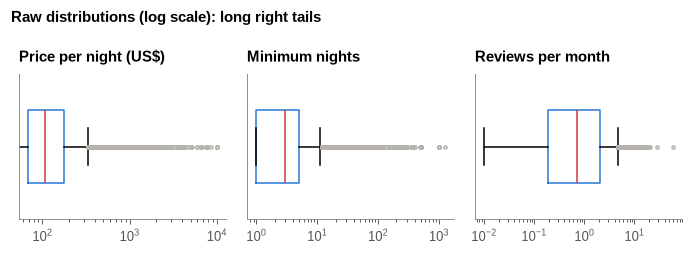

In [15]:
# @title 7.4 Outliers and impossible values

price_q = raw["price"].quantile([0.5, 0.9, 0.99, 0.999])
print("Price quantiles (US$):", price_q.to_dict())
print("Price = 0:", (raw["price"] == 0).sum())
print("Price > $1,000:", (raw["price"] > 1000).sum(), "| of which $9,999 or $10,000:", raw["price"].isin([9999, 10000]).sum())
print("Minimum nights > 365:", (raw["minimum_nights"] > 365).sum(), "| max:", raw["minimum_nights"].max())
print("Minimum nights >= 30:", (raw["minimum_nights"] >= 30).sum())
print("Availability = 0 days:", (raw["availability_365"] == 0).sum())
print("Highest review rate:", raw["reviews_per_month"].max())

fig, axes = plt.subplots(1, 3, figsize=(FIG_WIDTH, 2.3))
for ax, col, title in zip(axes, ["price", "minimum_nights", "reviews_per_month"],
                          ["Price per night (US$)", "Minimum nights", "Reviews per month"]):
    ax.boxplot(raw[col].dropna(), orientation="horizontal", widths=0.5, flierprops={"markersize": 2, "markeredgecolor": MUTED},
               medianprops={"color": CRITICAL}, boxprops={"color": PRIMARY})
    ax.set_xscale("log")
    ax.set_yticks([])
    ax.set_title(title)
fig.suptitle("Raw distributions (log scale): long right tails", x=0.01, ha="left", fontsize=9.5, fontweight="bold")
fig.tight_layout()
plt.show()

**Remark** ✅ The audit finds the following issues, all fixed in section 8:

| # | Issue | Rows | Decision |
|---|---|---|---|
| 1 | `last_review` and `reviews_per_month` missing | 10,052 (20.6 %) | **Structural**, not an error: they are missing exactly for the 10,052 listings with 0 reviews → rate set to 0, date left empty, flag `has_reviews` |
| 2 | `name` missing | 16 | set to *Unnamed listing* |
| 3 | `host_name` missing | 21 | column dropped (personal data, not needed) |
| 4 | Duplicates | 0 on id, 0 on all other columns, 1 identical offer on 6 key fields | nothing removed: listings with the same title (989) are different listings of the same host |
| 5 | Spaces around listing names | 254 | trimmed |
| 6 | `last_review` read as text | 38,843 | converted to a date |
| 7 | Price = \$0 | 11 | removed: a stay cannot be free |
| 8 | Price above \$1,000 per night | 239 (0.49 %), incl. 6 at \$9,999 or \$10,000 | removed from the analysis set: placeholders and luxury outliers that distort averages |
| 9 | Minimum nights above 365 (up to 1,250) | 14 | capped at 365 |
| 10 | Map file `New_York_City_.png` is in fact a **JPEG** | 1 file | read by its content |

Two values look extreme but are **kept** because they are plausible: 36 % of the listings have **0 days of availability** (calendar closed or fully booked) and one listing has **58.5 reviews per month** (a hotel-like room in the Theater District).

<a name="data-cleaning"></a>
# 8. Data Cleaning & Cleaned Dataset

Every step records the number of rows before and after, and the number of rows changed, in a **cleaning log** that is exported with the data and shown in the dashboard.

In [16]:
# @title Step 0: cleaning log

log = []


def record(step: str, action: str, frame: pd.DataFrame, rows_affected: int):
    """
    Adds one line to the cleaning log.

    Args:
        step: Short name of the step.
        action: What was done and why.
        frame: The table after the step.
        rows_affected: Number of rows changed or removed by the step.
    """
    log.append({"Step": len(log) + 1, "Name": step, "Action": action, "Rows Affected": int(rows_affected),
                "Rows After": len(frame), "Median Price After": float(frame["price"].median())})


df = raw.copy()
record("Raw file", "AB_NYC_2019.csv as supplied (48,895 listings, 16 columns)", df, 0)

In [17]:
# @title Step 1: duplicates

n_dup = df.duplicated(subset="id").sum()
df = df.drop_duplicates(subset="id")
record("Duplicates", "Checked on the listing id and on all the other columns: no duplicate found", df, n_dup)
print("Duplicates removed:", n_dup)

Duplicates removed: 0


In [18]:
# @title Step 2: unnecessary and personal columns

df = df.drop(columns=["host_name"])
record("Columns", "host_name dropped: personal data, not needed (host_id identifies the host); 16 columns -> 15", df, 0)
print(list(df.columns))

['id', 'name', 'host_id', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


In [19]:
# @title Step 3: text values (trim, missing names)

n_trim = (df["name"].str.strip() != df["name"]).sum()
df["name"] = df["name"].str.strip()
n_noname = df["name"].isna().sum()
df["name"] = df["name"].fillna("Unnamed listing")
for col in ["neighbourhood_group", "neighbourhood", "room_type"]:
    df[col] = df[col].str.strip()
record("Text", f"Spaces trimmed in {n_trim} names; {n_noname} missing names set to 'Unnamed listing'", df, n_trim + n_noname)

In [20]:
# @title Step 4: types (date, identifiers, categories)

df["last_review"] = pd.to_datetime(df["last_review"], format="%Y-%m-%d")
df["id"] = df["id"].astype("int64")
df["host_id"] = df["host_id"].astype("int64")
record("Types", "last_review converted from text to date; ids kept as integers; categories checked", df, df["last_review"].notna().sum())
print(df.dtypes)

id                                         int64
name                                         str
host_id                                    int64
neighbourhood_group                          str
neighbourhood                                str
latitude                                 float64
longitude                                float64
room_type                                    str
price                                      int64
minimum_nights                             int64
number_of_reviews                          int64
last_review                       datetime64[us]
reviews_per_month                        float64
calculated_host_listings_count             int64
availability_365                           int64
dtype: object


In [21]:
# @title Step 5: structural missing values (listings without any review)

n_norev = df["reviews_per_month"].isna().sum()
df["reviews_per_month"] = df["reviews_per_month"].fillna(0.0)
df["has_reviews"] = np.where(df["number_of_reviews"] > 0, "Yes", "No")
record("Missing reviews", f"{n_norev} listings never reviewed: reviews_per_month = 0; last_review kept empty (no date exists)", df, n_norev)

In [22]:
# @title Step 6: impossible prices (US$ 0 per night)

n_zero = (df["price"] <= 0).sum()
df = df[df["price"] > 0]
record("Price = 0", f"{n_zero} listings at $0 per night removed (a stay cannot be free; data entry error)", df, n_zero)

In [23]:
# @title Step 7: extreme prices (above US$ 1,000 per night)

PRICE_CAP = 1000
extreme = df[df["price"] > PRICE_CAP]
print(f"Above ${PRICE_CAP:,}: {len(extreme)} listings ({len(extreme) / len(df):.2%}), "
      f"{extreme['price'].isin([9999, 10000]).sum()} at $9,999 or $10,000")
print(extreme["price"].describe().round(0).to_dict())
df = df[df["price"] <= PRICE_CAP]
record("Price > $1,000", f"{len(extreme)} listings above $1,000 per night removed: placeholders ($9,999, $10,000) and luxury "
       f"outliers (0.5 % of listings) that distort averages; kept in the raw file", df, len(extreme))

Above $1,000: 239 listings (0.49%), 6 at $9,999 or $10,000
{'count': 239.0, 'mean': 2482.0, 'std': 1894.0, 'min': 1002.0, '25%': 1312.0, '50%': 1799.0, '75%': 2775.0, 'max': 10000.0}


In [24]:
# @title Step 8: minimum nights above one year

n_long = (df["minimum_nights"] > 365).sum()
df["minimum_nights"] = df["minimum_nights"].clip(upper=365)
record("Minimum nights", f"{n_long} values above 365 nights (up to 1,250) capped at 365: no booking rule can exceed one year", df, n_long)

In [25]:
# @title Step 9: derived columns for the analysis and the dashboard

REF_DATE = df["last_review"].max()          # 8 July 2019, date of the snapshot

price_bins = [0, 50, 100, 150, 200, 300, 500, PRICE_CAP]
price_labels = ["< $50", "$50-99", "$100-149", "$150-199", "$200-299", "$300-499", "$500-1,000"]
df["price_band"] = pd.cut(df["price"], bins=price_bins, labels=price_labels, right=False, include_lowest=True)
df.loc[df["price"] == PRICE_CAP, "price_band"] = "$500-1,000"
df["price_band_order"] = df["price_band"].cat.codes + 1

df["min_stay"] = pd.cut(df["minimum_nights"], bins=[0, 2, 6, 29, 365],
                        labels=["1-2 nights", "3-6 nights", "7-29 nights", "30+ nights"])
df["min_stay_order"] = df["min_stay"].cat.codes + 1

df["availability_band"] = pd.cut(df["availability_365"], bins=[-1, 0, 90, 180, 270, 365],
                                 labels=["0 days", "1-90 days", "91-180 days", "181-270 days", "271-365 days"])
df["availability_band_order"] = df["availability_band"].cat.codes + 1

df["host_size"] = pd.cut(df["calculated_host_listings_count"], bins=[0, 1, 5, 400],
                         labels=["1 listing", "2-5 listings", "6+ listings"])
df["host_size_order"] = df["host_size"].cat.codes + 1

df["last_review_year"] = df["last_review"].dt.year.astype("Int64")
df["days_since_review"] = (REF_DATE - df["last_review"]).dt.days.astype("Int64")
df["active_12m"] = np.where(df["days_since_review"].fillna(10_000) <= 365, "Yes", "No")
df["borough_order"] = df["neighbourhood_group"].map({b: i + 1 for i, b in enumerate(BOROUGHS)})
df["room_order"] = df["room_type"].map({r: i + 1 for i, r in enumerate(ROOMS)})
record("Derived columns", "price band, minimum-stay class, availability band, host size, year of last review, "
       "days since last review, active in the last 12 months, sort orders", df, len(df))
df.head()

,id,name,host_id,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,...,min_stay_order,availability_band,availability_band_order,host_size,host_size_order,last_review_year,days_since_review,active_12m,borough_order,room_order
0,2539,Clean & quiet apt home by the park,2787,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,...,1,271-365 days,5,6+ listings,3,2018,262,Yes,2,2
1,2595,Skylit Midtown Castle,2845,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,...,1,271-365 days,5,2-5 listings,2,2019,48,Yes,1,1
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,...,2,271-365 days,5,1 listing,1,<NA>,<NA>,No,1,2
3,3831,Cozy Entire Floor of Brownstone,4869,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,...,1,181-270 days,4,1 listing,1,2019,3,Yes,2,1
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,...,3,0 days,1,1 listing,1,2018,231,Yes,1,1


In [26]:
# @title Cleaning log and export of the cleaned dataset

cleaning_log = pd.DataFrame(log)
cleaning_log.to_csv(drive_processed_path + "cleaning_log.csv", index=False)

export = df.copy()
export["last_review"] = export["last_review"].dt.strftime("%Y-%m-%d")
for col in ["price_band", "min_stay", "availability_band", "host_size"]:
    export[col] = export[col].astype(str)
export.to_csv(drive_processed_path + "airbnb_nyc_clean.csv", index=False, encoding="utf-8")

kept = len(df) / len(raw)
show_message(f"✅ Cleaned dataset: {len(df):,} listings x {df.shape[1]} columns ({kept:.2%} of the raw listings kept)", "#228B22")
print(sorted(os.listdir(drive_processed_path)))
cleaning_log

['airbnb_nyc_clean.csv', 'cleaning_log.csv']


,Step,Name,Action,Rows Affected,Rows After,Median Price After
0,1,Raw file,"AB_NYC_2019.csv as supplied (48,895 listings, ...",0,48895,106.0
1,2,Duplicates,Checked on the listing id and on all the other...,0,48895,106.0
2,3,Columns,"host_name dropped: personal data, not needed (...",0,48895,106.0
3,4,Text,Spaces trimmed in 254 names; 16 missing names ...,270,48895,106.0
4,5,Types,last_review converted from text to date; ids k...,38843,48895,106.0
5,6,Missing reviews,10052 listings never reviewed: reviews_per_mon...,10052,48895,106.0
6,7,Price = 0,11 listings at $0 per night removed (a stay ca...,11,48884,106.0
7,8,"Price > $1,000","239 listings above $1,000 per night removed: p...",239,48645,105.0
8,9,Minimum nights,"14 values above 365 nights (up to 1,250) cappe...",14,48645,105.0
9,10,Derived columns,"price band, minimum-stay class, availability b...",48645,48645,105.0


**Remark** ✅ The cleaned dataset has **48,645 listings (99.49 % of the raw file)** and 29 columns: the 15 original columns kept and 14 derived columns (price band, minimum-stay class, availability band, host size, year of the last review, days since the last review, active in the last 12 months, sort orders). Only 250 listings were removed (11 at \$0 and 239 above \$1,000); the median price moves from \$106 to **\$105**, so the cleaning does not change the picture of a typical listing. The two files `airbnb_nyc_clean.csv` and `cleaning_log.csv` in `data/processed/` feed the dashboard.

<a name="kpis"></a>
# 9. KPIs

In [27]:
# @title Headline KPIs of the cleaned dataset

def top_count(column: str) -> str:
    """
    Returns the most frequent value of a column and its share of the listings.

    Args:
        column: Column name.

    Returns:
        A label such as 'Manhattan (44.3 %)'.
    """
    counts = df[column].value_counts()
    return f"{counts.index[0]} ({counts.iloc[0] / len(df):.1%})"


kpis = pd.Series({
    "Listings": f"{len(df):,}",
    "Hosts": f"{df['host_id'].nunique():,}",
    "Neighbourhoods": f"{df['neighbourhood'].nunique()}",
    "Median price per night": f"${df['price'].median():,.0f}",
    "Average price per night": f"${df['price'].mean():,.0f}",
    "Total reviews": f"{df['number_of_reviews'].sum():,}",
    "Listings with at least one review": f"{(df['number_of_reviews'] > 0).mean():.1%}",
    "Reviewed in the last 12 months": f"{(df['active_12m'] == 'Yes').mean():.1%}",
    "Median availability (days per year)": f"{df['availability_365'].median():.0f}",
    "Listings of multi-listing hosts": f"{(df['calculated_host_listings_count'] > 1).mean():.1%}",
    "Most common room type": top_count("room_type"),
    "Borough with most listings": top_count("neighbourhood_group"),
    "Neighbourhood with most listings": top_count("neighbourhood"),
})
kpis.to_frame("Value")

,Value
Listings,"48,645"
Hosts,"37,283"
Neighbourhoods,221
Median price per night,$105
Average price per night,$141
Total reviews,"1,136,096"
Listings with at least one review,79.6%
Reviewed in the last 12 months,59.8%
Median availability (days per year),44
Listings of multi-listing hosts,33.9%


**Remark** ✅ The New York market of the file is **48,645 listings offered by 37,283 hosts in 221 neighbourhoods**. A typical night costs **\$105** (median; mean \$141). Listings received **1.14 million reviews** in total; 80 % have at least one review and **60 % were reviewed in the last 12 months**, the share that is clearly active. Half of the listings are open less than **44 days** a year. One listing in three (**34 %**) belongs to a host who runs several listings. **Entire homes** (52 %), **Manhattan** (44 %) and **Williamsburg** (8 %) lead the offer.

<a name="eda"></a>
# 10. Exploratory Data Analysis

In [28]:
# @title Common objects for the figures

def save_figure(fig, name: str):
    """
    Saves a figure twice: PNG (300 dpi, notebook and README) and PDF (vector, report).

    Args:
        fig: The matplotlib figure.
        name: File name without extension.
    """
    for ext in ("png", "pdf"):
        fig.savefig(f"{drive_plots_path}{name}.{ext}", bbox_inches="tight", pad_inches=0.05)


def dollars(x: float, _=None) -> str:
    """
    Formats an axis tick in US dollars.

    Args:
        x: The tick value.

    Returns:
        The label, for example $150.
    """
    return f"${x:,.0f}"


# The map file is named .png but is a JPEG image (checked in section 7.3): PIL reads it by its content.
from PIL import Image

nyc_map = np.asarray(Image.open(MAP_FILE))
MAP_EXTENT = [-74.258, -73.69, 40.49, 40.92]     # longitude and latitude of the edges of the map image

# Light version of the same map for the figures: the grey levels of the file separate New York City (dark grey),
# the neighbouring land (light grey) and the water and district borders (white).
grey = nyc_map[..., 0].astype(int)
map_light = np.empty(nyc_map.shape, dtype=np.uint8)
map_light[grey <= 160] = (221, 228, 238)                     # New York City
map_light[(grey > 160) & (grey <= 215)] = (240, 241, 244)    # New Jersey, Westchester, Nassau
map_light[grey > 215] = (255, 255, 255)                      # water and district borders

## 10.1 What are the most common listing types? (Q1)

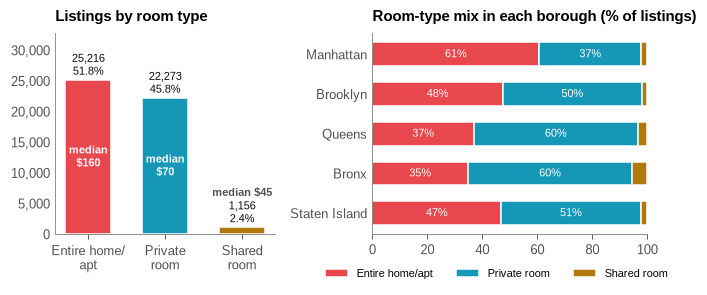

,Listings,Median_price,Mean_price,Reviews,Median_rpm,Share,Review share
room_type,,,,,,,
Entire home/apt,25216,160.0,194.612,578947,0.35,0.518,0.510
Private room,22273,70.0,84.787,537906,0.40,0.458,0.473
Shared room,1156,45.0,67.732,19243,0.41,0.024,0.017


In [29]:
# @title Figure 1: listings and median price by room type

room = df.groupby("room_type").agg(Listings=("id", "size"), Median_price=("price", "median"),
                                   Mean_price=("price", "mean"), Reviews=("number_of_reviews", "sum"),
                                   Median_rpm=("reviews_per_month", "median")).reindex(ROOMS)
room["Share"] = room["Listings"] / room["Listings"].sum()
room["Review share"] = room["Reviews"] / room["Reviews"].sum()
mix = pd.crosstab(df["neighbourhood_group"], df["room_type"], normalize="index").reindex(BOROUGHS)[ROOMS]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FIG_WIDTH, 2.8), gridspec_kw={"width_ratios": [1, 1.25]})
ax1.bar(range(3), room["Listings"], color=[ROOM_COLORS[r] for r in ROOMS], width=0.6, edgecolor="white", linewidth=1)
for i, (n, s, p) in enumerate(zip(room["Listings"], room["Share"], room["Median_price"])):
    ax1.text(i, n + 500, f"{n:,}\n{s:.1%}", ha="center", va="bottom", fontsize=7.5, color=INK, linespacing=1.1)
    if n > 5000:
        ax1.text(i, n / 2, f"median\n${p:,.0f}", ha="center", va="center", fontsize=7.5, color="white", fontweight="bold")
    else:
        ax1.text(i, n + 4700, f"median ${p:,.0f}", ha="center", va="bottom", fontsize=7.5, color=INK_SECONDARY, fontweight="bold")
ax1.set_xticks(range(3), ["Entire home/\napt", "Private\nroom", "Shared\nroom"])
ax1.set_ylim(0, room["Listings"].max() * 1.3)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax1.set_title("Listings by room type")
left = np.zeros(len(mix))
for r in ROOMS:
    ax2.barh(mix.index[::-1], mix[r].values[::-1] * 100, left=left[::-1], color=ROOM_COLORS[r], label=r, height=0.6,
             edgecolor="white", linewidth=1)
    for y, (l, v) in enumerate(zip(left[::-1], mix[r].values[::-1])):
        if v > 0.08:
            ax2.text(l + v * 50, y, f"{v:.0%}", ha="center", va="center", fontsize=7.5, color=ROOM_TEXT[r])
    left = left + mix[r].values * 100
ax2.set_xlim(0, 100)
ax2.set_title("Room-type mix in each borough (% of listings)")
ax2.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.45, -0.12), fontsize=7.5)
fig.tight_layout()
save_figure(fig, "fig01_room_types")
plt.show()
room.round(3)

**Remark** ✅ **Entire homes/apartments are the most common listing type (25,216 listings, 51.8 %)**, closely followed by **private rooms (22,273, 45.8 %)**; shared rooms are marginal (1,156, 2.4 %).

- The two main types are **two different products**: an entire home costs a median **\$160** per night, a private room **\$70** (less than half), a shared room \$45.
- The mix depends on the borough: entire homes dominate in **Manhattan (61 %)**, while **private rooms dominate in Queens and the Bronx (60 %)**, where hosts rent a room in their own home. Brooklyn and Staten Island are split half and half.
- Private rooms receive almost as many reviews as entire homes (47 % against 51 % of all reviews) with fewer listings: they are booked at least as often.

**For hosts and Airbnb:** the market is two markets. Prices, competition and guests must be compared within a room type, never across.

## 10.2 Which areas have the highest activity? (Q2)

Activity is measured on two sides: **supply** (number of listings) and **demand** (reviews, a review being left after a stay).

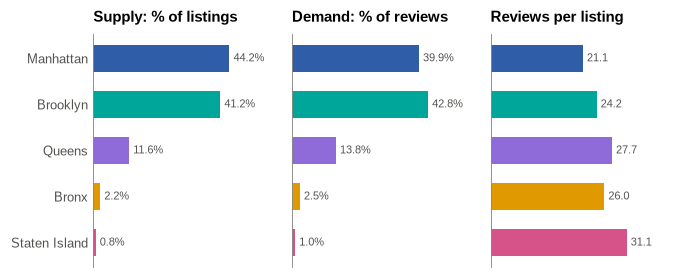

,Listings,Hosts,Reviews,Reviews_12m,Median_rpm,Median_price,Listing share,Review share,Reviews per listing
neighbourhood_group,,,,,,,,,
Manhattan,21488,16452,453413,11925,0.29,149.0,0.442,0.399,21.101
Brooklyn,20041,15926,485887,12202,0.38,90.0,0.412,0.428,24.245
Queens,5656,3976,156939,3873,0.76,75.0,0.116,0.138,27.747
Bronx,1089,789,28316,780,0.87,65.0,0.022,0.025,26.002
Staten Island,371,254,11541,300,1.00,75.0,0.008,0.010,31.108


In [30]:
# @title Figure 2: supply and demand by borough

boro = df.groupby("neighbourhood_group").agg(Listings=("id", "size"), Hosts=("host_id", "nunique"),
                                              Reviews=("number_of_reviews", "sum"),
                                              Reviews_12m=("active_12m", lambda s: (s == "Yes").sum()),
                                              Median_rpm=("reviews_per_month", "median"),
                                              Median_price=("price", "median")).reindex(BOROUGHS)
boro["Listing share"] = boro["Listings"] / boro["Listings"].sum()
boro["Review share"] = boro["Reviews"] / boro["Reviews"].sum()
boro["Reviews per listing"] = boro["Reviews"] / boro["Listings"]

fig, axes = plt.subplots(1, 3, figsize=(FIG_WIDTH, 2.6), sharey=True)
names = boro.index[::-1]
colors = [BOROUGH_COLORS[b] for b in names]
panels = [("Listing share", "Supply: % of listings", "{:.1%}"),
          ("Review share", "Demand: % of reviews", "{:.1%}"),
          ("Reviews per listing", "Reviews per listing", "{:.1f}")]
for ax, (col, title, fmt) in zip(axes, panels):
    vals = boro[col].values[::-1]
    ax.barh(names, vals, color=colors, height=0.6)
    for y, v in enumerate(vals):
        ax.text(v + vals.max() * 0.03, y, fmt.format(v), va="center", fontsize=7.5, color=INK_SECONDARY)
    ax.set_xlim(0, vals.max() * 1.35)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.set_title(title)
fig.tight_layout()
save_figure(fig, "fig02_boroughs")
plt.show()
boro.round(3)

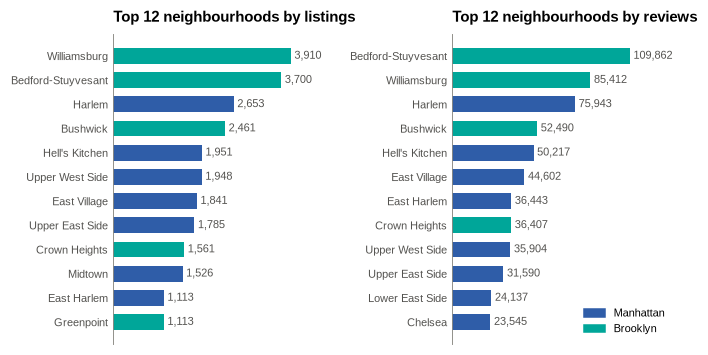

Top 10 neighbourhoods: 48.0% of the listings


,neighbourhood,neighbourhood_group,Listings,Reviews,Median_rpm,Median_price,Lat,Lon
214,Williamsburg,Brooklyn,3910,85412,0.30,105.0,40.71,-73.95
13,Bedford-Stuyvesant,Brooklyn,3700,109862,0.65,80.0,40.69,-73.94
94,Harlem,Manhattan,2653,75943,0.47,89.0,40.82,-73.95
28,Bushwick,Brooklyn,2461,52490,0.35,65.0,40.70,-73.92
95,Hell's Kitchen,Manhattan,1951,50217,0.53,166.0,40.76,-73.99
202,Upper West Side,Manhattan,1948,35904,0.18,150.0,40.79,-73.97
64,East Village,Manhattan,1841,44602,0.29,150.0,40.73,-73.98
201,Upper East Side,Manhattan,1785,31590,0.26,149.0,40.77,-73.95
51,Crown Heights,Brooklyn,1561,36407,0.33,85.0,40.67,-73.95
127,Midtown,Manhattan,1526,19330,0.13,208.5,40.75,-73.98


In [31]:
# @title Figure 3: the most active neighbourhoods

neigh = df.groupby(["neighbourhood", "neighbourhood_group"]).agg(
    Listings=("id", "size"), Reviews=("number_of_reviews", "sum"),
    Median_rpm=("reviews_per_month", "median"), Median_price=("price", "median"),
    Lat=("latitude", "mean"), Lon=("longitude", "mean")).reset_index()
top_list = neigh.nlargest(12, "Listings").iloc[::-1]
top_rev = neigh.nlargest(12, "Reviews").iloc[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FIG_WIDTH, 3.3))
for ax, data, col, title, fmt in [(ax1, top_list, "Listings", "Top 12 neighbourhoods by listings", "{:,.0f}"),
                                  (ax2, top_rev, "Reviews", "Top 12 neighbourhoods by reviews", "{:,.0f}")]:
    ax.barh(data["neighbourhood"], data[col], color=[BOROUGH_COLORS[b] for b in data["neighbourhood_group"]], height=0.65)
    for y, v in enumerate(data[col]):
        ax.text(v + data[col].max() * 0.02, y, fmt.format(v), va="center", fontsize=7, color=INK_SECONDARY)
    ax.set_xlim(0, data[col].max() * 1.25)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.set_title(title)
    ax.tick_params(axis="y", labelsize=7.5)
present = [b for b in BOROUGHS if b in set(top_list["neighbourhood_group"]) | set(top_rev["neighbourhood_group"])]
ax2.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BOROUGH_COLORS[b]) for b in present], labels=present,
           loc="lower right", fontsize=7)
fig.tight_layout()
save_figure(fig, "fig03_neighbourhoods")
plt.show()
print(f"Top 10 neighbourhoods: {neigh.nlargest(10, 'Listings')['Listings'].sum() / len(df):.1%} of the listings")
neigh.nlargest(10, "Listings").round(2)

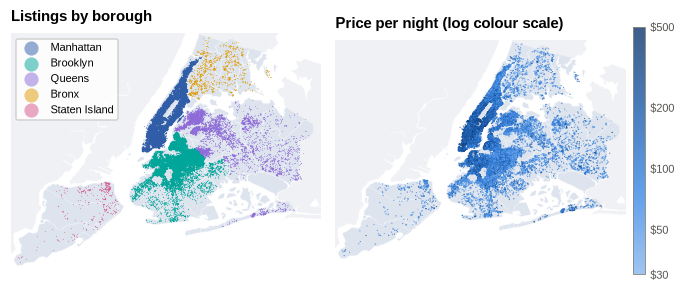

In [32]:
# @title Figure 4: where the listings are (map)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FIG_WIDTH, 3.25))
for ax in (ax1, ax2):
    ax.imshow(map_light, extent=MAP_EXTENT, zorder=0)
    ax.set_xlim(MAP_EXTENT[:2])
    ax.set_ylim(MAP_EXTENT[2:])
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
sample = df.sample(frac=1, random_state=1)
for b in BOROUGHS:
    pts = sample[sample["neighbourhood_group"] == b]
    ax1.scatter(pts["longitude"], pts["latitude"], s=0.6, color=BOROUGH_COLORS[b], alpha=0.5, label=b, linewidths=0)
ax1.legend(markerscale=12, fontsize=7, loc="upper left", frameon=True, framealpha=0.85)
ax1.set_title("Listings by borough")
price_cmap = matplotlib.colors.LinearSegmentedColormap.from_list("price_blue", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
sc = ax2.scatter(sample["longitude"], sample["latitude"], c=sample["price"], s=0.6, cmap=price_cmap,
                 norm=matplotlib.colors.LogNorm(vmin=30, vmax=500), alpha=0.8, linewidths=0)
cb = fig.colorbar(sc, ax=ax2, fraction=0.04, pad=0.02)
cb.set_ticks([30, 50, 100, 200, 500])
cb.set_ticklabels(["$30", "$50", "$100", "$200", "$500"])
cb.ax.minorticks_off()
cb.ax.tick_params(labelsize=7)
ax2.set_title("Price per night (log colour scale)")
fig.tight_layout()
save_figure(fig, "fig04_map")
plt.show()

**Remark** ✅ **Manhattan and Brooklyn concentrate the activity**: together they hold 85 % of the listings and 83 % of all reviews.

- **Supply:** Manhattan has the most listings (44.2 %), Brooklyn almost as many (41.2 %). The ten largest neighbourhoods hold **48 %** of all listings; **Williamsburg** (3,910) and **Bedford-Stuyvesant** (3,700) in Brooklyn lead, ahead of Harlem, Bushwick and Hell's Kitchen.
- **Demand:** **Brooklyn receives more reviews than Manhattan** (42.8 % against 39.9 %) with fewer listings, and **Bedford-Stuyvesant is the most reviewed neighbourhood** of the city (109,862 reviews, ahead of Williamsburg with 85,412).
- **Intensity:** the small boroughs are used more intensively: **Staten Island (31.1 reviews per listing), Queens (27.7) and the Bronx (26.0)** beat Manhattan (21.1). Their median review rate is three times higher (0.76 to 1.00 reviews per month against 0.29 in Manhattan).
- **Map:** listings spread from Midtown and Lower Manhattan into north Brooklyn and western Queens; prices are highest in Lower and Midtown Manhattan and fall with the distance from it.

**For hosts and Airbnb:** the busiest areas are not only the largest. Outer-borough listings are fewer but booked more often, a sign that **supply is short** where demand is high.

## 10.3 How do prices differ between areas? (Q3)

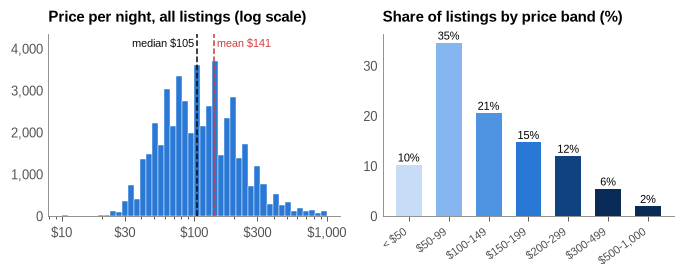

count    48645.0
mean       141.3
std        116.7
min         10.0
10%         49.0
25%         69.0
50%        105.0
75%        175.0
90%        259.0
max       1000.0
Name: price, dtype: float64

In [33]:
# @title Figure 5: price distribution

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FIG_WIDTH, 2.6))
bins = np.logspace(np.log10(10), np.log10(1000), 45)
ax1.hist(df["price"], bins=bins, color=PRIMARY, edgecolor="white", linewidth=0.3)
ax1.set_xscale("log")
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(dollars))
ax1.set_xticks([10, 30, 100, 300, 1000])
top = ax1.get_ylim()[1]
ax1.set_ylim(0, top * 1.12)
med, mean = df["price"].median(), df["price"].mean()
ax1.axvline(med, color=INK, lw=1, ls="--")
ax1.axvline(mean, color=CRITICAL, lw=1, ls="--")
ax1.text(med * 0.95, top * 1.04, f"median ${med:,.0f}", fontsize=7.5, color=INK, ha="right")
ax1.text(mean * 1.05, top * 1.04, f"mean ${mean:,.0f}", fontsize=7.5, color=CRITICAL, ha="left")
ax1.set_title("Price per night, all listings (log scale)")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
band = df["price_band"].value_counts().sort_index()
ax2.bar(range(len(band)), band.values / len(df) * 100, color=RAMP[:1] + RAMP[1:] + [RAMP[-1]] * 2, width=0.65)
for i, v in enumerate(band.values / len(df) * 100):
    ax2.text(i, v + 0.6, f"{v:.0f}%", ha="center", fontsize=7.5)
ax2.set_xticks(range(len(band)), band.index, rotation=35, ha="right", fontsize=7.5)
ax2.set_title("Share of listings by price band (%)")
fig.tight_layout()
save_figure(fig, "fig05_price_distribution")
plt.show()
df["price"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1)

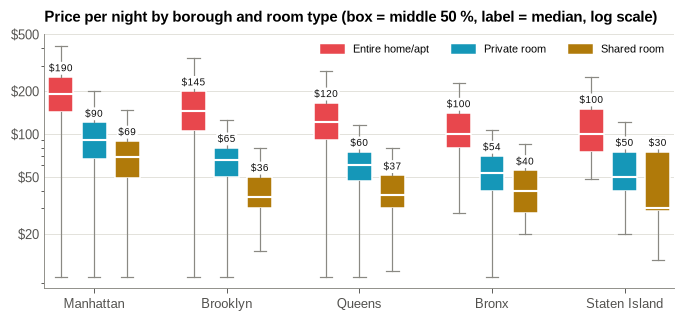

room_type,Entire home/apt,Private room,Shared room,All types
neighbourhood_group,,,,
Manhattan,190.0,90.0,69.0,149.0
Brooklyn,145.0,65.0,36.0,90.0
Queens,120.0,60.0,37.0,75.0
Bronx,100.0,53.5,40.0,65.0
Staten Island,100.0,50.0,30.0,75.0


In [34]:
# @title Figure 6: price by borough and room type

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.0))
pos, data, cols = [], [], []
for i, b in enumerate(BOROUGHS):
    for j, r in enumerate(ROOMS):
        vals = df.loc[(df["neighbourhood_group"] == b) & (df["room_type"] == r), "price"]
        pos.append(i * 4 + j)
        data.append(vals)
        cols.append(ROOM_COLORS[r])
bp = ax.boxplot(data, positions=pos, widths=0.75, patch_artist=True, showfliers=False,
                medianprops={"linewidth": 1.4}, whiskerprops={"color": AXIS, "linewidth": 0.8}, capprops={"color": AXIS, "linewidth": 0.8})
for k, (patch, c) in enumerate(zip(bp["boxes"], cols)):
    patch.set_facecolor(c)
    patch.set_edgecolor("white")
    bp["medians"][k].set_color("white")
for p_, vals in zip(pos, data):
    ax.text(p_, vals.quantile(0.75) * 1.06, f"${vals.median():,.0f}", ha="center", va="bottom", fontsize=6.3, color=INK,
            bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none"}, zorder=5)
ax.set_xticks([i * 4 + 1 for i in range(5)], BOROUGHS)
ax.set_yscale("log")
ax.set_yticks([20, 50, 100, 200, 500])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(dollars))
ax.grid(axis="y")
ax.set_title("Price per night by borough and room type (box = middle 50 %, label = median, log scale)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ROOM_COLORS[r]) for r in ROOMS], labels=ROOMS, ncol=3, loc="upper right", fontsize=7.5)
fig.tight_layout()
save_figure(fig, "fig06_price_borough_room")
plt.show()
price_table = df.pivot_table(index="neighbourhood_group", columns="room_type", values="price", aggfunc="median").reindex(BOROUGHS)[ROOMS]
price_table["All types"] = df.groupby("neighbourhood_group")["price"].median().reindex(BOROUGHS)
price_table

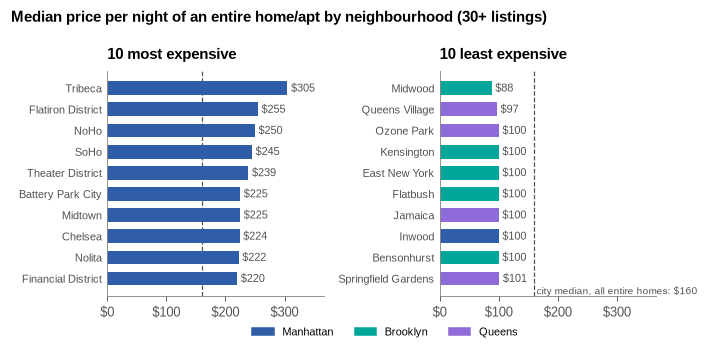

Neighbourhoods with 30+ entire homes: 81; ratio most/least expensive: 3.5x


In [35]:
# @title Figure 7: most and least expensive neighbourhoods (entire homes, at least 30 listings)

ent = df[df["room_type"] == "Entire home/apt"]
nb_price = ent.groupby(["neighbourhood", "neighbourhood_group"]).agg(Listings=("id", "size"), Median=("price", "median")).reset_index()
nb_price = nb_price[nb_price["Listings"] >= 30]
top_p, low_p = nb_price.nlargest(10, "Median"), nb_price.nsmallest(10, "Median")
city_median = ent["price"].median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FIG_WIDTH, 3.0), sharex=True)
for ax, data, title in [(ax1, top_p.iloc[::-1], "10 most expensive"), (ax2, low_p.sort_values("Median", ascending=False), "10 least expensive")]:
    ax.barh(data["neighbourhood"], data["Median"], color=[BOROUGH_COLORS[b] for b in data["neighbourhood_group"]], height=0.65)
    for y, v in enumerate(data["Median"]):
        ax.text(v + 6, y, f"${v:,.0f}", va="center", fontsize=7, color=INK_SECONDARY)
    ax.axvline(city_median, color=INK_SECONDARY, lw=0.8, ls="--", zorder=0)
    ax.set_title(title)
    ax.tick_params(axis="y", labelsize=7.5)
ax2.text(city_median + 4, -0.6, f"city median, all entire homes: ${city_median:,.0f}", fontsize=6.5, va="center", color=INK_SECONDARY)
ax1.set_xlim(0, top_p["Median"].max() * 1.2)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(dollars))
present = [b for b in BOROUGHS if b in set(top_p["neighbourhood_group"]) | set(low_p["neighbourhood_group"])]
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BOROUGH_COLORS[b]) for b in present], labels=present,
           loc="lower center", ncol=len(present), fontsize=7, bbox_to_anchor=(0.55, -0.04))
fig.suptitle("Median price per night of an entire home/apt by neighbourhood (30+ listings)", x=0.01, ha="left", fontsize=9.5, fontweight="bold")
fig.tight_layout()
save_figure(fig, "fig07_neighbourhood_prices")
plt.show()
print(f"Neighbourhoods with 30+ entire homes: {len(nb_price)}; ratio most/least expensive: {top_p['Median'].max() / low_p['Median'].min():.1f}x")

**Remark** ✅ **Prices fall with the distance from Manhattan, and the room type matters as much as the borough.**

- **Distribution:** the median night costs **\$105** and the mean \$141 (pulled up by expensive listings); 35 % of the listings ask \$50 to \$99 and only 8 % ask \$300 or more.
- **By borough (median, all types):** Manhattan **\$149**, Brooklyn \$90, Queens and Staten Island \$75, Bronx **\$65**. For an entire home: Manhattan \$190, Brooklyn \$145, Queens \$120, Bronx and Staten Island \$100.
- **Inside every borough, an entire home costs about twice a private room**, and the spread inside a borough is wide (the boxes overlap): location explains only part of the price.
- **By neighbourhood (entire homes, 30+ listings):** **Tribeca (\$305)**, Flatiron District, NoHo and SoHo are the most expensive; the least expensive are in Brooklyn and Queens (Midwood \$88, Queens Village \$97). The ratio between the most and the least expensive is **3.5 to 1**.

**For hosts:** benchmark a price against the same room type in the same neighbourhood, not against the city average.

## 10.4 Is there a relationship between price, ratings and number of reviews? (Q4)

⚠️ **The dataset has no rating column** (no stars, no review score). The relationship is studied between **price** and the two review variables that exist: `number_of_reviews` (accumulated since the listing was created) and `reviews_per_month` (the rate, a better proxy of current demand). Ratings would require another source, which the brief does not allow.

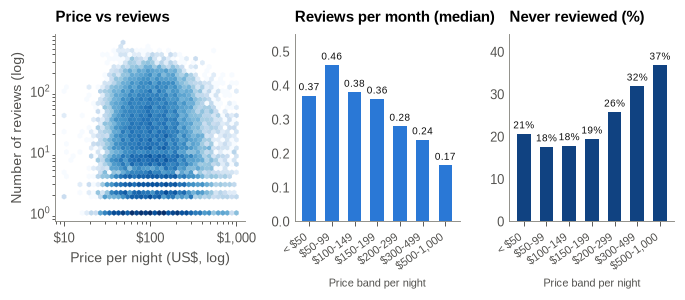

Spearman price vs number of reviews: rho = -0.049 (p = 1.4e-27)
Spearman price vs reviews per month: rho = -0.054 (p = 6.0e-33)


,Listings,Median_reviews,Median_rpm,Never_reviewed
price_band,,,,
< $50,5016,4.0,0.370,0.206
$50-99,16850,6.0,0.460,0.176
$100-149,10033,6.0,0.380,0.178
$150-199,7200,6.0,0.360,0.194
$200-299,5867,4.0,0.280,0.258
$300-499,2683,3.0,0.240,0.319
"$500-1,000",996,2.0,0.165,0.368


In [36]:
# @title Figure 8: price and reviews

reviewed = df[df["number_of_reviews"] > 0]
by_band = df.groupby("price_band", observed=True).agg(Listings=("id", "size"),
                                                      Median_reviews=("number_of_reviews", "median"),
                                                      Median_rpm=("reviews_per_month", "median"),
                                                      Never_reviewed=("number_of_reviews", lambda s: (s == 0).mean()))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(FIG_WIDTH, 2.8), gridspec_kw={"width_ratios": [1.15, 1, 1]})
hb = ax1.hexbin(reviewed["price"], reviewed["number_of_reviews"], gridsize=38, xscale="log", yscale="log",
                bins="log", cmap="Blues", mincnt=1, linewidths=0.1)
ax1.set_xlabel("Price per night (US$, log)")
ax1.set_ylabel("Number of reviews (log)")
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(dollars))
ax1.set_title("Price vs reviews")
x = np.arange(len(by_band))
ax2.bar(x, by_band["Median_rpm"], color=PRIMARY, width=0.6)
for i, v in enumerate(by_band["Median_rpm"]):
    ax2.text(i, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=6.8, color=INK)
ax2.set_ylim(0, by_band["Median_rpm"].max() * 1.2)
ax2.set_title("Reviews per month (median)")
ax3.bar(x, by_band["Never_reviewed"] * 100, color=RAMP[4], width=0.6)
for i, v in enumerate(by_band["Never_reviewed"]):
    ax3.text(i, v * 100 + 0.8, f"{v:.0%}", ha="center", va="bottom", fontsize=6.8, color=INK)
ax3.set_ylim(0, by_band["Never_reviewed"].max() * 120)
ax3.set_title("Never reviewed (%)")
for ax in (ax2, ax3):
    ax.set_xticks(x, by_band.index, rotation=35, ha="right", fontsize=7)
    ax.set_xlabel("Price band per night", fontsize=7.5)
fig.tight_layout()
save_figure(fig, "fig08_price_reviews")
plt.show()
rho_n = stats.spearmanr(df["price"], df["number_of_reviews"])
rho_r = stats.spearmanr(df["price"], df["reviews_per_month"])
print(f"Spearman price vs number of reviews: rho = {rho_n.statistic:.3f} (p = {rho_n.pvalue:.1e})")
print(f"Spearman price vs reviews per month: rho = {rho_r.statistic:.3f} (p = {rho_r.pvalue:.1e})")
by_band.round(3)

In [37]:
# @title Same relationship inside each room type

rows = []
for r in ROOMS:
    sub = df[df["room_type"] == r]
    rows.append({"Room type": r, "Listings": len(sub),
                 "rho price-reviews": stats.spearmanr(sub["price"], sub["number_of_reviews"]).statistic,
                 "rho price-reviews/month": stats.spearmanr(sub["price"], sub["reviews_per_month"]).statistic})
pd.DataFrame(rows).round(3)

,Room type,Listings,rho price-reviews,rho price-reviews/month
0,Entire home/apt,25216,-0.125,-0.078
1,Private room,22273,-0.004,-0.018
2,Shared room,1156,-0.058,-0.123


**Remark** ✅ **There is no rating column**, so the question is answered with reviews. The result is clear: **price and number of reviews are almost unrelated** (Spearman ρ = -0.05 with the number of reviews and -0.05 with the review rate; significant because the sample is large, but negligible in size).

- Listings at \$50 to \$99 have the highest median review rate (0.46 per month); above \$200 the rate falls steadily to **0.17** for \$500-1,000.
- The share of listings **never reviewed** rises with the price, from **18 %** around \$50-150 to **37 %** above \$500: expensive listings are booked less often or are rarely active.
- Inside each room type the link stays weak (ρ between -0.13 and 0.00).

**What it means:** many reviews do not justify a higher price, and a high price does not bring more stays. Reviews measure **demand**, and demand is concentrated on affordable listings. **Ratings** (satisfaction) cannot be studied with this dataset; this is a limit, not a finding.

## 10.5 What factors appear to affect listing prices? (Q5)

The figures above look at one factor at a time. A **multiple regression of the log of the price** measures each factor **with the others held constant** (section 11 gives the model details). The effect of each factor is read as a percentage difference in the price of a comparable listing.

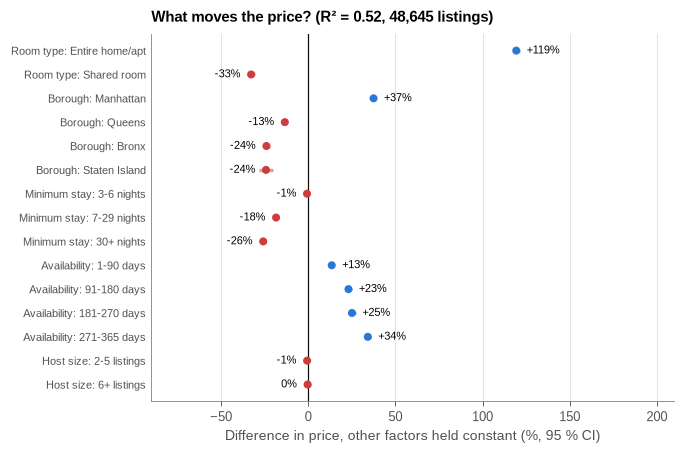

,Factor,Level,Effect %,Low %,High %,p
Level,,,,,,
Entire home/apt,room,Entire home/apt,119.335,117.381,121.307,0.000
Shared room,room,Shared room,-32.759,-35.068,-30.367,0.000
Manhattan,borough,Manhattan,37.464,36.205,38.734,0.000
Queens,borough,Queens,-13.428,-14.554,-12.287,0.000
Bronx,borough,Bronx,-23.998,-26.124,-21.810,0.000
Staten Island,borough,Staten Island,-24.219,-28.052,-20.183,0.000
3-6 nights,stay,3-6 nights,-0.690,-1.648,0.277,0.161
7-29 nights,stay,7-29 nights,-18.450,-19.642,-17.241,0.000
30+ nights,stay,30+ nights,-25.832,-27.178,-24.460,0.000


In [38]:
# @title Figure 9: price effect of each factor (multiple regression on log price)

model_df = df.assign(log_price=np.log(df["price"]),
                     log_reviews=np.log1p(df["number_of_reviews"]),
                     borough=df["neighbourhood_group"], room=df["room_type"],
                     stay=df["min_stay"].astype(str), avail=df["availability_band"].astype(str),
                     host=df["host_size"].astype(str))
formula = ("log_price ~ C(room, Treatment('Private room')) + C(borough, Treatment('Brooklyn')) "
           "+ C(stay, Treatment('1-2 nights')) + C(avail, Treatment('0 days')) + C(host, Treatment('1 listing')) + log_reviews")
ols = smf.ols(formula, data=model_df).fit(cov_type="HC3")
ci = ols.conf_int()
effects = pd.DataFrame({"coef": ols.params, "low": ci[0], "high": ci[1], "p": ols.pvalues}).drop("Intercept")
effects = effects[~effects.index.str.startswith("log_reviews")]
effects["Effect %"] = (np.exp(effects["coef"]) - 1) * 100
effects["Low %"] = (np.exp(effects["low"]) - 1) * 100
effects["High %"] = (np.exp(effects["high"]) - 1) * 100
effects["Factor"] = effects.index.str.extract(r"C\((\w+)", expand=False).values
effects["Level"] = effects.index.str.extract(r"\[T\.(.+)\]", expand=False).values
group_names = {"room": "Room type (vs private room)", "borough": "Borough (vs Brooklyn)",
               "stay": "Minimum stay (vs 1-2 nights)", "avail": "Availability (vs 0 days)", "host": "Host size (vs 1 listing)"}
level_order = ["Entire home/apt", "Shared room", "Manhattan", "Queens", "Bronx", "Staten Island", "3-6 nights", "7-29 nights",
               "30+ nights", "1-90 days", "91-180 days", "181-270 days", "271-365 days", "2-5 listings", "6+ listings"]
effects = effects.set_index("Level", drop=False).loc[level_order]
plot_df = effects.iloc[::-1]

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4.2))
y = np.arange(len(plot_df))
colors = [CRITICAL if v < 0 else PRIMARY for v in plot_df["Effect %"]]
ax.hlines(y, plot_df["Low %"], plot_df["High %"], color=colors, lw=2.2, alpha=0.5)
ax.scatter(plot_df["Effect %"], y, color=colors, s=18, zorder=3)
for yy, v in zip(y, plot_df["Effect %"]):
    label = "0%" if abs(v) < 0.5 else f"{v:+.0f}%"
    ax.text(v + (6 if v >= 0 else -6), yy, label, va="center", ha="left" if v >= 0 else "right", fontsize=7)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(y, [f"{group_names[f].split(' (')[0]}: {l}" for f, l in zip(plot_df["Factor"], plot_df["Level"])], fontsize=7.5)
ax.set_xlabel("Difference in price, other factors held constant (%, 95 % CI)")
ax.set_xlim(-90, 210)
ax.grid(axis="x")
ax.set_title(f"What moves the price? (R² = {ols.rsquared:.2f}, {int(ols.nobs):,} listings)")
fig.tight_layout()
save_figure(fig, "fig09_price_factors")
plt.show()
effects[["Factor", "Level", "Effect %", "Low %", "High %", "p"]].round(3)

In [39]:
# @title How much of the price variation does each factor explain on its own?

single = {}
for name, term in [("Room type", "C(room)"), ("Borough", "C(borough)"), ("Neighbourhood", "C(neighbourhood)"),
                   ("Minimum stay", "C(stay)"), ("Availability", "C(avail)"), ("Host size", "C(host)"),
                   ("Reviews (log)", "log_reviews")]:
    single[name] = smf.ols(f"log_price ~ {term}", data=model_df).fit().rsquared
full_nb = smf.ols("log_price ~ C(room) + C(neighbourhood) + C(stay) + C(avail) + C(host) + log_reviews", data=model_df).fit()
r2 = pd.Series(single).sort_values(ascending=False).to_frame("R² alone")
print(f"Full model with the neighbourhood instead of the borough: R² = {full_nb.rsquared:.3f}")
r2.round(3)

Full model with the neighbourhood instead of the borough: R² = 0.589


,R² alone
Room type,0.409
Neighbourhood,0.287
Borough,0.137
Host size,0.023
Minimum stay,0.015
Availability,0.011
Reviews (log),0.003


**Remark** ✅ **Three factors drive the price: the room type, the location and the way the listing is operated.** The model explains **52 %** of the variation of the (log) price (59 % with the 221 neighbourhoods instead of the 5 boroughs). The rest depends on what the file does not contain (size, quality, amenities).

- **Room type is the strongest factor**: alone it explains 41 % of the variation. Other things equal, an **entire home costs +119 %** (more than double) compared with a private room; a shared room **-33 %**.
- **Location comes second**: the neighbourhood explains 29 % on its own, the borough 14 %. Compared with Brooklyn, a comparable listing costs **+37 % in Manhattan**, -13 % in Queens and -24 % in the Bronx and Staten Island.
- **Minimum stay:** listings that require **30+ nights are 26 % cheaper** per night (7-29 nights: -18 %): they are monthly rentals with a lower nightly rate.
- **Availability:** listings open most of the year are **13 % to 34 % more expensive** than those closed (0 days), the pattern of full-time professional listings.
- **Host size has no effect** once room type and location are taken into account (≈ 0 %), and more reviews go with slightly lower prices (-5 % per unit of log reviews).

**For hosts:** what a listing **is** (an entire home) and **where** it is set most of the price; pricing above the benchmark of the area needs a reason the data cannot see (size, quality, view).

## 10.6 Which listings or areas show the strongest performance? (Q6)

Without bookings or revenue, **performance** is measured by **demand**: the review rate (reviews per month), which grows with the number of stays. It is compared with the **price**, so that an area that is both busy and well priced stands out. Only neighbourhoods with at least 50 listings are ranked, so that a few listings cannot make an area look strong.

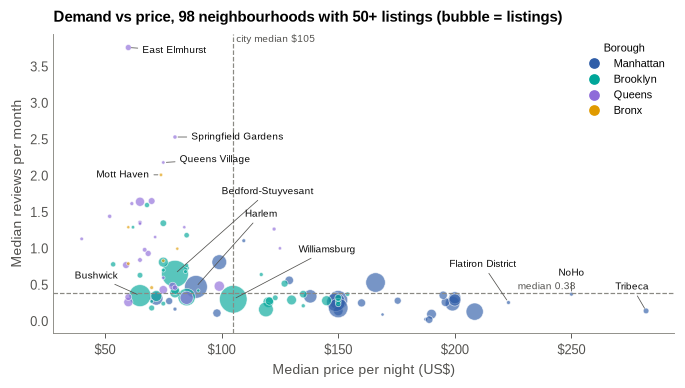

,neighbourhood,neighbourhood_group,Listings,Median_rpm,Median_price
59,East Elmhurst,Queens,185,3.76,60.0
183,Springfield Gardens,Queens,85,2.53,80.0
160,Queens Village,Queens,60,2.18,75.0
134,Mott Haven,Bronx,60,2.01,74.0
105,Jamaica,Queens,231,1.65,70.0
77,Flushing,Queens,425,1.64,65.0
185,St. Albans,Queens,76,1.62,61.5
52,Cypress Hills,Brooklyn,134,1.60,68.0
217,Woodhaven,Queens,88,1.44,52.0
164,Richmond Hill,Queens,94,1.36,65.0


In [40]:
# @title Figure 10: demand and price by neighbourhood

nb = neigh[neigh["Listings"] >= 50].copy()
med_rpm, med_price = df["reviews_per_month"].median(), df["price"].median()

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 3.6))
for b in BOROUGHS:
    sub = nb[nb["neighbourhood_group"] == b]
    ax.scatter(sub["Median_price"], sub["Median_rpm"], s=sub["Listings"] / 12, color=BOROUGH_COLORS[b], alpha=0.65,
               edgecolor="white", linewidth=0.5, label=b)
ax.axvline(med_price, color=AXIS, lw=0.8, ls="--")
ax.axhline(med_rpm, color=AXIS, lw=0.8, ls="--")
to_label = pd.concat([nb.nlargest(4, "Median_rpm"), nb.nlargest(3, "Median_price"), nb.nlargest(4, "Listings")]).drop_duplicates("neighbourhood")
# label positions in data units (price, reviews per month), chosen in the empty parts of the chart
LABEL_AT = {"East Elmhurst": (66, 3.72, "left"), "Springfield Gardens": (87, 2.53, "left"), "Queens Village": (82, 2.22, "left"),
            "Mott Haven": (69, 2.01, "right"), "Bedford-Stuyvesant": (100, 1.78, "left"), "Harlem": (110, 1.47, "left"),
            "Williamsburg": (133, 0.98, "left"), "Bushwick": (37, 0.62, "left"), "Flatiron District": (212, 0.78, "center"),
            "NoHo": (250, 0.66, "center"), "Tribeca": (276, 0.47, "center")}
for _, r in to_label.iterrows():
    tx, ty, ha = LABEL_AT.get(r["neighbourhood"], (r["Median_price"] + 5, r["Median_rpm"] + 0.1, "left"))
    ax.annotate(r["neighbourhood"], (r["Median_price"], r["Median_rpm"]), xytext=(tx, ty), textcoords="data",
                fontsize=6.5, color=INK, ha=ha, va="center",
                arrowprops={"arrowstyle": "-", "color": INK_SECONDARY, "lw": 0.5, "shrinkA": 1, "shrinkB": 2})
ax.set_xlabel("Median price per night (US$)")
ax.set_ylabel("Median reviews per month")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(dollars))
ax.text(227, med_rpm + 0.03, f"median {med_rpm:.2f}", fontsize=6.3, va="bottom", ha="left", color=INK_SECONDARY)
ax.text(med_price, ax.get_ylim()[1], f" city median ${med_price:,.0f}", fontsize=6.3, va="top", ha="left", color=INK_SECONDARY)
ax.set_title(f"Demand vs price, {len(nb)} neighbourhoods with 50+ listings (bubble = listings)")
shown = [b for b in BOROUGHS if b in set(nb["neighbourhood_group"])]
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=BOROUGH_COLORS[b], ms=6) for b in shown], labels=shown,
          fontsize=7, loc="upper right", title="Borough", title_fontsize=7)
fig.tight_layout()
save_figure(fig, "fig10_performance")
plt.show()
nb.nlargest(10, "Median_rpm")[["neighbourhood", "neighbourhood_group", "Listings", "Median_rpm", "Median_price"]].round(2)

In [41]:
# @title Top 10 listings by demand (reviews per month), and top listings by total reviews

cols = ["name", "neighbourhood", "neighbourhood_group", "room_type", "price", "number_of_reviews", "reviews_per_month", "last_review"]
top_rpm = df.nlargest(10, "reviews_per_month")[cols]
top_reviews = df.nlargest(10, "number_of_reviews")[cols]
print("Rooms in the top 100 by reviews per month:", df.nlargest(100, "reviews_per_month")["room_type"].value_counts().to_dict())
print("Boroughs in the top 100 by reviews per month:", df.nlargest(100, "reviews_per_month")["neighbourhood_group"].value_counts().to_dict())
top_rpm

Rooms in the top 100 by reviews per month: {'Private room': 64, 'Entire home/apt': 33, 'Shared room': 3}
Boroughs in the top 100 by reviews per month: {'Queens': 63, 'Manhattan': 18, 'Brooklyn': 17, 'Bronx': 1, 'Staten Island': 1}


,name,neighbourhood,neighbourhood_group,room_type,price,number_of_reviews,reviews_per_month,last_review
42075,Enjoy great views of the City in our Deluxe Room!,Theater District,Manhattan,Private room,100,156,58.50,2019-07-07
42076,Great Room in the heart of Times Square!,Theater District,Manhattan,Private room,199,82,27.95,2019-07-07
38870,Lou's Palace-So much for so little,Rosedale,Queens,Private room,45,37,20.94,2019-07-08
27287,JFK Comfort.5 Mins from JFK Private Bedroom & ...,Springfield Gardens,Queens,Private room,80,403,19.75,2019-07-06
28651,JFK 2 Comfort 5 Mins from JFK Private Bedroom,Springfield Gardens,Queens,Private room,50,341,17.82,2019-07-08
29628,JFK 3 Comfort 5 Mins from JFK Private Bedroom,Springfield Gardens,Queens,Private room,50,302,16.81,2019-07-06
20403,Cozy Room Family Home LGA Airport NO CLEANING FEE,East Elmhurst,Queens,Private room,48,510,16.22,2019-07-06
22469,Cute Tiny Room Family Home by LGA NO CLEANING FEE,East Elmhurst,Queens,Private room,48,436,16.03,2019-07-08
36238,“For Heaven Cakes”,Springfield Gardens,Queens,Entire home/apt,75,132,15.78,2019-07-05
40297,Studio Apartment 6 minutes from JFK Airport,Jamaica,Queens,Private room,67,95,15.32,2019-07-05


In [42]:
top_reviews

,name,neighbourhood,neighbourhood_group,room_type,price,number_of_reviews,reviews_per_month,last_review
11759,Room near JFK Queen Bed,Jamaica,Queens,Private room,47,629,14.58,2019-07-05
2031,Great Bedroom in Manhattan,Harlem,Manhattan,Private room,49,607,7.75,2019-06-21
2030,Beautiful Bedroom in Manhattan,Harlem,Manhattan,Private room,49,597,7.72,2019-06-23
2015,Private Bedroom in Manhattan,Harlem,Manhattan,Private room,49,594,7.57,2019-06-15
13495,Room Near JFK Twin Beds,Jamaica,Queens,Private room,47,576,13.40,2019-06-27
10623,Steps away from Laguardia airport,East Elmhurst,Queens,Private room,46,543,11.59,2019-07-01
1879,Manhattan Lux Loft.Like.Love.Lots.Look !,Lower East Side,Manhattan,Private room,99,540,6.95,2019-07-06
20403,Cozy Room Family Home LGA Airport NO CLEANING FEE,East Elmhurst,Queens,Private room,48,510,16.22,2019-07-06
4870,Private brownstone studio Brooklyn,Park Slope,Brooklyn,Entire home/apt,160,488,8.14,2019-07-01
471,LG Private Room/Family Friendly,Bushwick,Brooklyn,Private room,60,480,6.70,2019-07-07


**Remark** ✅ **The strongest demand is in Queens, near the airports, for cheap private rooms.**

- **Areas:** among the 98 neighbourhoods with 50+ listings, the highest median review rates are **East Elmhurst (3.76 reviews per month, next to LaGuardia airport)**, **Springfield Gardens (2.53, next to JFK)**, Queens Village, Mott Haven (Bronx), Jamaica and Flushing; all have a median price of \$60 to \$80. They sit in the upper-left corner of the chart: **cheap and busy**.
- **Large central areas are less intensive**: Williamsburg, Midtown and the Upper West Side have many listings but low median review rates (0.13 to 0.30), because their supply is large and their prices high.
- **Listings:** 63 of the 100 listings with the highest review rate are in **Queens** and 64 are **private rooms**; their titles often name the airport ("5 mins from JFK", "LGA airport"). The most reviewed listing of the city is a **\$47 room near JFK (629 reviews)**. Two Theater District rooms at the top (58.5 and 28 reviews per month) look like **hotel rooms** sold on Airbnb.
- **Manhattan's expensive neighbourhoods** (Tribeca, NoHo, Flatiron) are in the lower-right corner: high price, low review rate.

**For hosts and Airbnb:** there are two winning models: **volume** (affordable rooms near airports and transport, many short stays) and **value** (expensive central homes, fewer stays). An outer-borough host competes on price and convenience, a Manhattan host on location.

## 10.7 Are there any clear patterns or trends in the data? (Q7)

Three patterns stand out: the **recency of use** (date of the last review), the **availability and minimum-stay rules**, and the **concentration of hosts**.

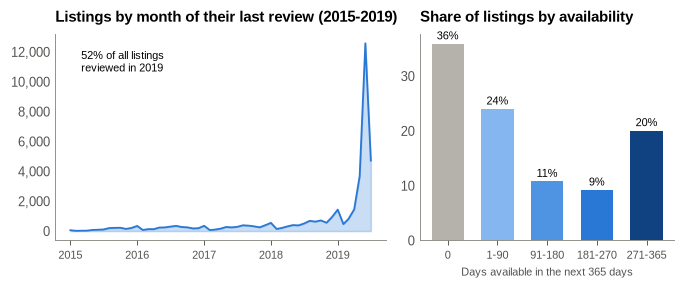

Last review year: {np.int64(2011): 7, np.int64(2012): 25, np.int64(2013): 47, np.int64(2014): 199, np.int64(2015): 1383, np.int64(2016): 2695, np.int64(2017): 3193, np.int64(2018): 6029, np.int64(2019): 25148}
Never reviewed: 9919


availability_band,0 days,1-90 days,91-180 days,181-270 days,271-365 days
room_type,,,,,
Entire home/apt,0.350,0.241,0.107,0.111,0.191
Private room,0.375,0.239,0.111,0.073,0.203
Shared room,0.256,0.255,0.073,0.052,0.364


In [43]:
# @title Figure 11: recency of the last review and availability

monthly = df.dropna(subset=["last_review"]).set_index("last_review").resample("MS").size()
monthly = monthly[monthly.index >= "2015-01-01"]
avail = df["availability_band"].value_counts().sort_index()
avail_room = pd.crosstab(df["room_type"], df["availability_band"], normalize="index").reindex(ROOMS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FIG_WIDTH, 2.7), gridspec_kw={"width_ratios": [1.3, 1]})
ax1.fill_between(monthly.index, monthly.values, color=PRIMARY, alpha=0.25)
ax1.plot(monthly.index, monthly.values, color=PRIMARY, lw=1.2)
ax1.set_title("Listings by month of their last review (2015-2019)")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax1.xaxis.set_major_locator(matplotlib.dates.YearLocator())
ax1.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%Y"))
ax1.tick_params(axis="x", labelsize=7.5)
share_2019 = (df["last_review_year"] == 2019).sum() / len(df)
ax1.text(monthly.index[2], monthly.max() * 0.85, f"{share_2019:.0%} of all listings\nreviewed in 2019", fontsize=7.5)
ax2.bar(range(len(avail)), avail.values / len(df) * 100, color=[MUTED] + RAMP[1:5], width=0.65)
for i, v in enumerate(avail.values / len(df) * 100):
    ax2.text(i, v + 0.8, f"{v:.0f}%", ha="center", fontsize=7.5)
ax2.set_xticks(range(len(avail)), [s.replace(" days", "") for s in avail.index], fontsize=7.5)
ax2.set_xlabel("Days available in the next 365 days", fontsize=7.5)
ax2.set_title("Share of listings by availability")
fig.tight_layout()
save_figure(fig, "fig11_recency_availability")
plt.show()
print("Last review year:", df["last_review_year"].value_counts().sort_index().to_dict())
print("Never reviewed:", (df["number_of_reviews"] == 0).sum())
avail_room.round(3)

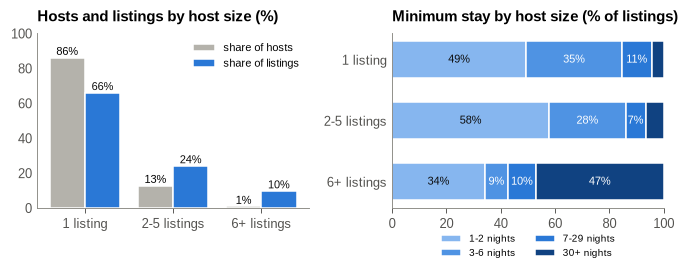

Hosts: 37,283 | top 10 hosts: 1,268 listings (2.6%)


,Listings,Hosts,Median_price,Entire_share,Median_avail,Thirty_plus,Listing share,Host share
host_size,,,,,,,,
1 listing,32135,32135,117.0,0.587,6.0,0.045,0.661,0.862
2-5 listings,11755,4805,85.0,0.332,115.0,0.066,0.242,0.129
6+ listings,4755,343,128.0,0.517,310.0,0.470,0.098,0.009


In [44]:
# @title Figure 12: who are the hosts? (concentration) and minimum stays

hosts = df.groupby("host_id").size()
host_tab = df.groupby("host_size", observed=True).agg(Listings=("id", "size"), Hosts=("host_id", "nunique"),
                                                      Median_price=("price", "median"),
                                                      Entire_share=("room_type", lambda s: (s == "Entire home/apt").mean()),
                                                      Median_avail=("availability_365", "median"),
                                                      Thirty_plus=("minimum_nights", lambda s: (s >= 30).mean()))
host_tab["Listing share"] = host_tab["Listings"] / host_tab["Listings"].sum()
host_tab["Host share"] = host_tab["Hosts"] / host_tab["Hosts"].sum()
stay = pd.crosstab(df["host_size"], df["min_stay"], normalize="index")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FIG_WIDTH, 2.6))
x = np.arange(len(host_tab))
ax1.bar(x - 0.2, host_tab["Host share"] * 100, 0.4, color=MUTED, label="share of hosts", edgecolor="white", linewidth=1)
ax1.bar(x + 0.2, host_tab["Listing share"] * 100, 0.4, color=PRIMARY, label="share of listings", edgecolor="white", linewidth=1)
for i, (a, b) in enumerate(zip(host_tab["Host share"], host_tab["Listing share"])):
    ax1.text(i - 0.2, a * 100 + 1.5, f"{a:.0%}", ha="center", fontsize=7)
    ax1.text(i + 0.2, b * 100 + 1.5, f"{b:.0%}", ha="center", fontsize=7, color=INK)
ax1.set_xticks(x, host_tab.index)
ax1.set_ylim(0, 100)
ax1.set_title("Hosts and listings by host size (%)")
ax1.legend(fontsize=7)
left = np.zeros(len(stay))
stay_cols = list(stay.columns)
for k, c in enumerate(stay_cols):
    ax2.barh(stay.index.astype(str)[::-1], stay[c].values[::-1] * 100, left=left[::-1], color=RAMP[k + 1], label=c, height=0.6,
             edgecolor="white", linewidth=1)
    for yy, (l, v) in enumerate(zip(left[::-1], stay[c].values[::-1])):
        if v > 0.07:
            ax2.text(l + v * 50, yy, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if k > 0 else INK)
    left = left + stay[c].values * 100
ax2.set_xlim(0, 100)
ax2.set_title("Minimum stay by host size (% of listings)")
ax2.legend(ncol=2, fontsize=6.5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
save_figure(fig, "fig12_hosts")
plt.show()
top_hosts = df.groupby("host_id").agg(Listings=("id", "size"), Median_price=("price", "median"),
                                      Main_borough=("neighbourhood_group", lambda s: s.mode()[0]),
                                      Entire_share=("room_type", lambda s: (s == "Entire home/apt").mean())).nlargest(10, "Listings")
print(f"Hosts: {len(hosts):,} | top 10 hosts: {top_hosts['Listings'].sum():,} listings ({top_hosts['Listings'].sum() / len(df):.1%})")
host_tab.round(3)

In [45]:
top_hosts.round(2)

,Listings,Median_price,Main_borough,Entire_share
host_id,,,,
219517861,327,228.0,Manhattan,0.98
107434423,232,302.5,Manhattan,1.00
30283594,119,239.0,Manhattan,1.00
137358866,103,41.0,Queens,0.02
12243051,96,209.5,Manhattan,1.00
16098958,96,180.0,Manhattan,0.99
61391963,91,142.0,Manhattan,1.00
22541573,87,210.0,Manhattan,1.00
200380610,65,250.0,Manhattan,1.00


**Remark** ✅ Three patterns stand out:

1. **A large part of the supply is inactive.** Only **60 %** of the listings were reviewed in the last 12 months and **20 %** were never reviewed; the last review of 52 % of all listings falls in 2019, with a sharp peak in June-July 2019 (the active listings). **36 % of the listings have 0 days of availability** (calendar closed), while 20 % are open almost all year.
2. **Demand goes with availability and short stays:** the review rate rises with availability (ρ = +0.30) and falls with the minimum stay (ρ = -0.25).
3. **Two kinds of hosts:** **86 % of hosts have a single listing** and hold 66 % of the offer, with a median availability of only **6 days**: occasional home sharing. At the other end, **343 hosts (0.9 %) run 6+ listings** and hold **10 % of the offer** (4,755 listings), open a median **310 days** a year, and **47 % of their listings require 30+ nights**: professional operators of furnished apartments, mostly entire homes in Manhattan (the 10 largest hosts alone run 1,268 listings). For the same room type, multi-listing hosts ask more for entire homes (median \$175 against \$155) and less for rooms.

**For the city and Airbnb:** the activity of professional operators is concentrated, visible and measurable with this file (host size, availability, minimum stay); the occasional host is the majority but offers few nights.

<a name="statistical-tests"></a>
# 11. Statistical Tests and Price Model

Prices and review counts are strongly skewed, so the tests are **non-parametric** (they compare ranks, not means): Kruskal-Wallis for several groups, Mann-Whitney for two groups, Spearman for correlations. With almost 49,000 listings, almost every difference is "significant"; the **effect size** says whether it matters.

In [46]:
# @title Kruskal-Wallis: does the price differ between boroughs, room types, host sizes?

def kruskal_effect(groups: list) -> tuple:
    """
    Kruskal-Wallis test with its effect size epsilon-squared.

    Args:
        groups: List of samples (one per group).

    Returns:
        (H statistic, p-value, epsilon-squared).
    """
    h, p = stats.kruskal(*groups)
    n = sum(len(g) for g in groups)
    return h, p, h / (n - 1)


rows = []
for name, col in [("Borough", "neighbourhood_group"), ("Room type", "room_type"), ("Host size", "host_size"),
                  ("Minimum stay", "min_stay"), ("Neighbourhood", "neighbourhood")]:
    groups = [g["price"].values for _, g in df.groupby(col, observed=True)]
    h, p, e2 = kruskal_effect(groups)
    rows.append({"Factor": name, "Groups": len(groups), "H": h, "p-value": p, "epsilon²": e2})
kw = pd.DataFrame(rows)
kw.round(4)

,Factor,Groups,H,p-value,epsilon²
0,Borough,5,6954.0304,0.0,0.1430
1,Room type,3,22425.1353,0.0,0.4610
2,Host size,3,1305.3389,0.0,0.0268
3,Minimum stay,4,805.5906,0.0,0.0166
4,Neighbourhood,221,14557.0948,0.0,0.2993


In [47]:
# @title Spearman correlations with bootstrap 95 % confidence intervals

def spearman_ci(x: pd.Series, y: pd.Series, n_boot: int = 500) -> tuple:
    """
    Spearman correlation with a bootstrap 95 % confidence interval.

    Args:
        x: First variable.
        y: Second variable.
        n_boot: Number of bootstrap samples.

    Returns:
        (rho, lower bound, upper bound).
    """
    rng = np.random.default_rng(42)
    rho = stats.spearmanr(x, y).statistic
    xs, ys = x.to_numpy(), y.to_numpy()
    boots = [stats.spearmanr(xs[i], ys[i]).statistic for i in (rng.integers(0, len(xs), len(xs)) for _ in range(n_boot))]
    return rho, np.percentile(boots, 2.5), np.percentile(boots, 97.5)


pairs = [("price", "number_of_reviews"), ("price", "reviews_per_month"), ("price", "availability_365"),
         ("price", "minimum_nights"), ("price", "calculated_host_listings_count"),
         ("reviews_per_month", "availability_365"), ("reviews_per_month", "minimum_nights")]
corr_rows = []
for a, b in pairs:
    rho, lo, hi = spearman_ci(df[a], df[b])
    corr_rows.append({"Variable 1": a, "Variable 2": b, "rho": rho, "CI low": lo, "CI high": hi})
corr_table = pd.DataFrame(corr_rows)
corr_table.round(3)

,Variable 1,Variable 2,rho,CI low,CI high
0,price,number_of_reviews,-0.049,-0.059,-0.041
1,price,reviews_per_month,-0.054,-0.064,-0.045
2,price,availability_365,0.083,0.075,0.093
3,price,minimum_nights,0.103,0.093,0.111
4,price,calculated_host_listings_count,-0.106,-0.116,-0.097
5,reviews_per_month,availability_365,0.301,0.293,0.310
6,reviews_per_month,minimum_nights,-0.250,-0.259,-0.242


In [48]:
# @title Mann-Whitney: do multi-listing hosts ask more for the same room type?

rows = []
for r in ROOMS:
    sub = df[df["room_type"] == r]
    single_ = sub.loc[sub["calculated_host_listings_count"] == 1, "price"]
    multi_ = sub.loc[sub["calculated_host_listings_count"] > 1, "price"]
    u, p = stats.mannwhitneyu(multi_, single_)
    rows.append({"Room type": r, "Median single host": single_.median(), "Median multi-listing host": multi_.median(),
                 "p-value": p, "Prob. multi > single": u / (len(multi_) * len(single_))})
mw = pd.DataFrame(rows)
mw.round(3)

,Room type,Median single host,Median multi-listing host,p-value,Prob. multi > single
0,Entire home/apt,155.0,175.0,0.0,0.553
1,Private room,70.0,67.0,0.0,0.470
2,Shared room,65.0,38.0,0.0,0.273


In [49]:
# @title Price model: summary of the regression of section 10.5

print(f"Observations: {int(ols.nobs):,} | R²: {ols.rsquared:.3f} | adjusted R²: {ols.rsquared_adj:.3f} | robust (HC3) standard errors")
print(f"Effect of +1 on log(1 + reviews): {(np.exp(ols.params['log_reviews']) - 1) * 100:+.1f}% "
      f"(p = {ols.pvalues['log_reviews']:.1e})")
ols.summary().tables[1]

Observations: 48,645 | R²: 0.516 | adjusted R²: 0.516 | robust (HC3) standard errors
Effect of +1 on log(1 + reviews): -5.0% (p = 6.3e-235)


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,4.2219,0.006,743.447,0.000,4.211,4.233
"C(room, Treatment('Private room'))[T.Entire home/apt]",0.7854,0.005,171.985,0.000,0.776,0.794
"C(room, Treatment('Private room'))[T.Shared room]",-0.3969,0.018,-22.261,0.000,-0.432,-0.362
"C(borough, Treatment('Brooklyn'))[T.Bronx]",-0.2744,0.014,-18.953,0.000,-0.303,-0.246
"C(borough, Treatment('Brooklyn'))[T.Manhattan]",0.3182,0.005,67.775,0.000,0.309,0.327
"C(borough, Treatment('Brooklyn'))[T.Queens]",-0.1442,0.007,-21.588,0.000,-0.157,-0.131
"C(borough, Treatment('Brooklyn'))[T.Staten Island]",-0.2773,0.026,-10.474,0.000,-0.329,-0.225
"C(stay, Treatment('1-2 nights'))[T.3-6 nights]",-0.0069,0.005,-1.401,0.161,-0.017,0.003
"C(stay, Treatment('1-2 nights'))[T.30+ nights]",-0.2988,0.009,-31.973,0.000,-0.317,-0.281
"C(stay, Treatment('1-2 nights'))[T.7-29 nights]",-0.2040,0.008,-27.160,0.000,-0.219,-0.189


**Remark** ✅ The tests confirm the reading of the figures:

- **Kruskal-Wallis:** all price differences are significant (p < 0.001), but their size varies a lot: **room type** (ε² = 0.46) and **neighbourhood** (ε² = 0.30) matter; borough (0.14) is moderate; host size (0.03) and minimum stay (0.02) are small.
- **Spearman with 95 % confidence intervals:** price vs reviews ρ = -0.05 [-0.06; -0.04], negligible; the strongest links are between **demand and availability** (+0.30) and **demand and minimum stay** (-0.25).
- **Mann-Whitney:** multi-listing hosts ask more for entire homes (probability of a higher price 55 %) and less for shared rooms (27 %).
- **Price model:** R² = 0.52 on 48,645 listings with robust standard errors; all effects of room type, borough, minimum stay and availability are significant, host size is not.

<a name="powerbi"></a>
# 12. The Power BI Dashboard

The dashboard, **`powerbi/NYC_Airbnb_Dashboard.pbix`**, is built on the **cleaned tables of section 8** (`data/processed/`), so its figures are the figures of this notebook. The Power Query steps are kept in `powerbi/PowerQuery_pipeline.m` and the DAX measures in `powerbi/DAX_measures.dax`.

## 12.1 Data model

| Table | Rows | Role |
|---|---|---|
| `Listings` | 48,645 | fact table: one row per listing (the cleaned dataset) |
| `Cleaning Log` | 10 | the steps of section 8, shown on the Data Pipeline page |

## 12.2 Measures (DAX)

44 measures, among them: `Total Listings`, `Total Hosts`, `Median Price`, `Average Price`, `Median Price Entire Home`, `Median Price Private Room` (with `KEEPFILTERS`, so that they respect the room-type filter), `Premium Listings %` (\$300 or more), `Total Reviews`, `Reviews per Listing`, `Median Reviews per Month`, `Reviewed Last 12 Months %`, `Never Reviewed %`, `Closed Calendar %`, `Multi-listing Host Share`, `Listings per Host`, `Hosts with 6+ Listings`, `Listing Share` and `Host Share` (with `ALLSELECTED`), `City Median Price` (with `ALL`, the reference of the gauge), the counts of the cleaning log (`Raw Listings`, `Removed Listings`, `Kept %`), and the ranking measures `Median Price (30+ listings)` and `Median Reviews per Month (50+ listings)`, which return a value only when the group is large enough to be compared.

## 12.3 Pages

**Design:** the style of the Movie Analytics dashboard: a dark navy theme with a single blue accent, a header band with a soft glow, the logo, the title and a **page navigator**, framed visuals with their titles and KPI cards with rounded borders. A **row of five synchronised slicers (Borough, Neighbourhood, Room type, Price per night, Minimum stay)** runs along the four analysis pages. Colours keep the hues of this notebook for the boroughs and the room types, lightened for the dark background; single measures are blue. The Home page uses the photo of the New York skyline supplied with the project; the map places each listing on the map supplied with the dataset. Icons: Microsoft Fluent Emoji 3D (MIT licence).

| Page | Visuals (question) |
|---|---|
| **1. Home** | skyline photo · 8 KPI cards · word cloud of the neighbourhoods · picture tiles to the Map, Prices and Demand pages · scrolling band of the largest neighbourhoods |
| **2. Map & Boroughs** | map of the 48,645 listings by borough (Q2) · listings by borough (Q2) · listing types (Q1) · median price by borough (Q3) |
| **3. Prices** | median price by borough and room type (Q3) · listings by price band (Q3) · gauge: median vs city median · ten most expensive neighbourhoods (Q3) · median price by minimum stay (Q5) |
| **4. Demand** | demand vs price by neighbourhood (Q6) · ten busiest listings (Q6) · reviews per month by borough (Q2) and by price band (Q4) · listings by year of their last review (Q7) |
| **5. Hosts** | hosts and listings by host size · minimum stay by host size · listings per host, hosts with 6+ listings · days open in the year · multi-listing hosts by borough (Q7) |
| **6. Insights** | the nine insights and the recommendations of section 13 |
| **7. Data Pipeline** | raw, removed and clean listings · the steps from the supplied file to the model · the cleaning log (sections 7-8) |

**Readability:** cards, axes and tables show business labels instead of measure names; value axes are hidden where the values are written on the bars; tooltips add a second figure; every visual has an alternative text. The 44 measures are grouped in display folders with a description.

**Interactivity:** the five slicers keep their selection across the four analysis pages; a click on a bar, a slice or a point filters the other visuals of the page; the cards, the gauge and the top-ten visuals follow every selection; the page navigator and the picture tiles move between the pages.

In [50]:
# @title Expected values of the dashboard (check after opening it, with no filter)

expected = pd.DataFrame({
    "Card / visual": ["Total Listings", "Total Hosts", "Median Price", "Average Price", "Total Reviews",
                      "Avg Availability (days)", "Reviewed in Last 12 Months", "Multi-listing Host Share",
                      "Top Borough (listings)", "Manhattan median price", "Entire home/apt share"],
    "Expected value": [f"{len(df):,}", f"{df['host_id'].nunique():,}", f"${df['price'].median():,.0f}",
                       f"${df['price'].mean():,.2f}", f"{df['number_of_reviews'].sum():,}",
                       f"{df['availability_365'].mean():.1f}", f"{(df['active_12m'] == 'Yes').mean():.1%}",
                       f"{(df['calculated_host_listings_count'] > 1).mean():.1%}",
                       df["neighbourhood_group"].value_counts().index[0],
                       f"${df.loc[df['neighbourhood_group'] == 'Manhattan', 'price'].median():,.0f}",
                       f"{(df['room_type'] == 'Entire home/apt').mean():.1%}"],
})
expected

,Card / visual,Expected value
0,Total Listings,"48,645"
1,Total Hosts,"37,283"
2,Median Price,$105
3,Average Price,$141.31
4,Total Reviews,"1,136,096"
5,Avg Availability (days),112.4
6,Reviewed in Last 12 Months,59.8%
7,Multi-listing Host Share,33.9%
8,Top Borough (listings),Manhattan
9,Manhattan median price,$149


<a name="insights"></a>
# 13. Insights & Recommendations

## Main insights

| # | What we discovered | What it means | Evidence |
|---|---|---|---|
| 1 | **Entire homes (52 %) and private rooms (46 %)** make the market; an entire home costs a median \$160, a private room \$70. | Two different products with two different guests; they must be priced and compared separately. | Fig. 1 |
| 2 | **Manhattan and Brooklyn hold 85 % of the listings**; Brooklyn receives the most reviews and Bedford-Stuyvesant is the most reviewed neighbourhood. | Brooklyn weighs as much as Manhattan in supply and leads in demand. | Fig. 2, 3, 4 |
| 3 | **Outer boroughs are used more intensively** (Staten Island 31, Queens 28 reviews per listing vs 21 in Manhattan). | Supply is short where demand per listing is high. | Fig. 2 |
| 4 | **Prices fall with the distance from Manhattan**: median \$149 in Manhattan, \$65 in the Bronx; Tribeca \$305 vs Midwood \$88 for an entire home. | Location sets the price level; the room type sets the product. | Fig. 5, 6, 7 |
| 5 | **Room type (+119 % for an entire home) and location (+37 % in Manhattan vs Brooklyn) explain most of the price**; 30+ night stays are 26 % cheaper; host size has no effect. | A host controls the price mainly through what and where they offer, and the minimum stay. | Fig. 9, Sec. 11 |
| 6 | **Price and reviews are almost unrelated** (ρ = -0.05); expensive listings are more often never reviewed (37 % above \$500). | Reviews follow affordability, not price; there are no ratings to test quality. | Fig. 8 |
| 7 | **The strongest demand is near the airports in Queens** (East Elmhurst 3.76, Springfield Gardens 2.53 reviews per month), for cheap private rooms. | Convenience and price win short stays. | Fig. 10 |
| 8 | **40 % of the listings were not reviewed in the last 12 months** and 36 % have a closed calendar. | Headline counts over-state the active supply. | Fig. 11 |
| 9 | **0.9 % of hosts run 10 % of the listings**, open 310 days a year, half with 30+ night minimum stays. | A small group of professional operators behaves differently from home sharers. | Fig. 12 |

## Recommendations

**For hosts**
1. **Price against the right benchmark:** the median of the same room type in the same neighbourhood (Prices page), not the city average; a price far above it needs a visible reason.
2. **Consider the outer boroughs and transport hubs:** rooms near JFK and LaGuardia and in Queens are booked far more often, at a median of \$60-80.
3. **Open the calendar and shorten the minimum stay** if the goal is short-term stays: demand rises with availability (ρ = +0.30) and falls with the minimum stay (ρ = -0.25).

**For Airbnb**
4. **Activate dormant supply:** 20 % of the listings were never reviewed and 36 % have a closed calendar; reminders, pricing tips or delisting would make search results more reliable.
5. **Recruit hosts where demand per listing is high** (Queens, Bronx, Staten Island) rather than in saturated central areas.
6. **Segment the offer by guest type:** affordable rooms for short, convenience-driven trips; entire homes in Manhattan for leisure and families; monthly rentals for longer stays.

**For the city**
7. **Monitor the professional segment:** host size, availability and minimum stay identify the operators of many entire homes (343 hosts with 4,755 listings) and allow targeted checks of the rules on short-term rentals, without burdening occasional home sharers.

**For the next analysis**
8. **Add ratings, bookings and property size** (from a future authorised source) to move from demand proxies to satisfaction, occupancy and revenue.

In [51]:
# @title Save the main result tables

room.round(4).to_csv(drive_results_path + "room_types.csv")
boro.round(4).to_csv(drive_results_path + "boroughs.csv")
neigh.sort_values("Listings", ascending=False).round(4).to_csv(drive_results_path + "neighbourhoods.csv", index=False)
price_table.round(1).to_csv(drive_results_path + "median_price_borough_room.csv")
by_band.round(4).to_csv(drive_results_path + "reviews_by_price_band.csv")
effects[["Factor", "Level", "Effect %", "Low %", "High %", "p"]].round(4).to_csv(drive_results_path + "price_model_effects.csv")
kw.round(5).to_csv(drive_results_path + "kruskal_wallis.csv", index=False)
corr_table.round(4).to_csv(drive_results_path + "correlations.csv", index=False)
host_tab.round(4).to_csv(drive_results_path + "host_size.csv")
top_rpm.to_csv(drive_results_path + "top10_listings_reviews_per_month.csv", index=False)
kpis.to_frame("Value").to_csv(drive_results_path + "kpis.csv")
print(sorted(os.listdir(drive_results_path)))

['boroughs.csv', 'correlations.csv', 'host_size.csv', 'kpis.csv', 'kruskal_wallis.csv', 'median_price_borough_room.csv', 'neighbourhoods.csv', 'price_model_effects.csv', 'reviews_by_price_band.csv', 'room_types.csv', 'top10_listings_reviews_per_month.csv']


<a name="limitations"></a>
# 14. Limitations & Future Works

**Limitations**
- **No ratings:** the question on ratings is answered with review counts and rates, which measure demand, not satisfaction.
- **No bookings or revenue:** prices are asked prices; demand is approximated by reviews (not every guest leaves a review).
- **No property size or quality:** bedrooms, bathrooms, capacity and amenities are missing, which explains why the price model stops at R² = 0.52.
- **One snapshot:** time patterns come from the date of the last review only; the growth of the market cannot be measured.
- **Cleaning choices:** listings above \$1,000 per night (0.5 %) are excluded from the analysis; the luxury segment is therefore not covered.
- **Map:** the background map is an image without coordinates; its position is set by hand and the overlay is approximate.

**Future works**
- Repeat the analysis on several snapshots to measure trends and seasonality.
- Add review scores and the calendar to study satisfaction and occupancy.
- Model the price with the size of the property and the distance to transport and landmarks.

<a name="references"></a>
# 15. References

1. Data Analysis Internship, Task 12: `AB_NYC_2019.csv` and `New_York_City_.png`, dataset supplied for the final project.
2. McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56-61.
3. Gebru, T. et al. (2021). Datasheets for Datasets. *Communications of the ACM*, 64(12), 86-92.
4. Kruskal, W. H., & Wallis, W. A. (1952). Use of ranks in one-criterion variance analysis. *Journal of the American Statistical Association*, 47(260), 583-621.
5. Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*.
6. Microsoft. *Power BI documentation: Power Query M reference, DAX function reference*. https://learn.microsoft.com/power-bi/